# M115 — TP3
## Grain, modèle et ETL dépendant du modèle
### Notebook étudiant à compléter · Kaggle · Python/Pandas
**Pr. AMINA ABOULMIRA · ENSAB**

| Identification du binôme | À renseigner |
|---|---|
| Étudiant(e) 1 — nom et prénom | **MOUHIB Wissal** |
| Date de réalisation | 20/11/2026 |
| Lien ou titre du notebook Kaggle | TP3 M115 — Grain, modèle et ETL — Wissal Mouhib |

**Mission :** transformer les données préparées L2 en un modèle décisionnel cohérent, alimenté et contrôlé : **L3**.

**Durée : 4 h.** Travail en binômes. Alternez les rôles : l’un écrit et l’autre vérifie, puis échangez. Les questions complémentaires renforcent les notions étudiées jusqu’à C4 ; elles n’ajoutent pas une évaluation ou un second projet.

Ce notebook est un **support de travail**, pas un corrigé : rédigez vos réponses dans les cellules Markdown, écrivez le code dans les cellules prévues et conservez vos sorties.

## Notre parcours du TP3 — illustration à ajouter

<table><tr><td style="border:2px dashed #42A9D7;padding:45px;text-align:center">
<strong>EMPLACEMENT RÉSERVÉ À L’IMAGE DU PARCOURS TP3</strong><br><br>
L’enseignante ajoutera ici son illustration des étapes.<br>
L2 → grain → modèle → dimensions → rattachement des clés → fait → contrôles → L3.
</td></tr></table>

<!-- Remplacer ce bloc par votre illustration, ou insérer une cellule image juste ici. Aucun lien d’image externe n’est imposé. -->

## Avant de commencer

Les **CSV seront fournis**. L’entrée principale est la source préparée du TP2, normalement nommée `TP2_L2_SOURCE_PREPAREE.csv`. Les autres fichiers L2 servent de traces et de contrôles. N’utilisez pas le brut `Online_Retail.csv` comme entrée de ce TP.

1. Ajouter les CSV fournis aux données du notebook Kaggle.
2. Exécuter la cellule d’environnement ci-dessous, puis identifier le chemin exact du fichier préparé.
3. Travailler dans l’ordre, avec les noms de DataFrames imposés.
4. Ne pas refaire le filtrage ou le dédoublonnage du TP2. Si L2 pose problème, documenter l’écart avant de poursuivre.
5. Répondre avant de coder, puis confronter la réponse aux sorties réelles.

**Modèle MVP :** `FactVente + DimDate + DimProduit + DimClient + DimPays`.

**Règles maintenues :** ventes positives de produits commerciaux ; client absent conservé ; pays disponible ; aucune catégorie inventée ; `InvoiceNo` reste dans le fait ; aucun dédoublonnage sur `InvoiceNo + StockCode` seuls.

Power BI n’est pas requis ici. **Le prochain TP portera sur l’OLAP**, à partir de L3.

### Repères de validation
- **CP3 — Grain :** expliquer exactement ce que représente une ligne.
- **CP4 — Modèle :** justifier faits, dimensions, mesures, clés et relations.
- **CP5 — Alimentation :** prouver que le chargement conserve les ventes et respecte les références.

### Temps proposé, réflexion et contrôles compris
| Étapes | Travail | Temps |
|---|---|---:|
| 1–4 | Entrée, grain, mesures, modèle | 65 min |
| 5–8 | Dimensions et client inconnu | 65 min |
| 9–10 | Lookups et fait | 45 min |
| 11–13 | Contrôles, architecture et débogage | 50 min |
| 14 | Export L3 et bilan | 15 min |
| **Total** | | **240 min** |

In [1]:
# ENVIRONNEMENT FOURNI — exécuter cette cellule sans reconstruire les sources.
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display

DOSSIER_ENTREE = Path("/kaggle/input")
DOSSIER_SORTIE = Path("/kaggle/working")
DOSSIER_SORTIE.mkdir(parents=True, exist_ok=True)

csv_disponibles = sorted(DOSSIER_ENTREE.rglob("*.csv"))
print("CSV disponibles :")
for chemin in csv_disponibles:
    print(chemin)

# À compléter avec le chemin réellement fourni ; ce paramètre ne charge rien à lui seul.
CHEMIN_L2 = ""

CSV disponibles :
/kaggle/input/tp2-l2-source-preparee/TP2_L2_SOURCE_PREPAREE.csv


## Contrat des noms à respecter

| Nom dans ce notebook | Contenu attendu |
|---|---|
| `df_prep` | CSV L2 chargé ; référence à conserver sans modification |
| `df` | Copie de travail pour les colonnes dérivées du modèle |
| `dim_date` | Dimension au grain du jour |
| `dim_produit` | Couples code / description normalisée distincts |
| `dim_client` | Clients identifiés et membre « Client inconnu » |
| `dim_pays` | Pays distincts de la source |
| `df_rattache` | Ventes enrichies des quatre clés dimensionnelles |
| `fact_vente` | Fait final exporté sous le nom FactVente |
| `controles_l3` | Tableau des preuves calculées |

**Noms des tables exportées :** DimDate, DimProduit, DimClient, DimPays et FactVente. Les noms Python en minuscules ne changent pas les noms du modèle.

**Mesures du fait :** `QuantiteVendue`, `PrixUnitaire`, `MontantLigne`. Les deux premières correspondent à `Quantity` et `UnitPrice` de L2 ; ce mapping doit être documenté.

# ÉTAPE 01 — Vérifier l’entrée L2 et situer la chaîne BI
**Durée indicative : 15 min · Objectif :** Comprendre les fichiers reçus avant de les transformer.



## Questions du TP
1. Comment passer d’une source préparée à un modèle multidimensionnel cohérent et contrôlable ?
2. Quelles structures faut-il construire pour analyser les ventes selon le temps, le produit, le client et le pays sans changer le sens des données ?

## Question complémentaire — prendre du recul
Dans la chaîne sources → staging → préparation / intégration → entrepôt → exploitation, où se situe L2 ? Quelles opérations du TP2 ne faut-il pas refaire ici ?

### Réponses

| Fichier CSV fourni | Rôle / usage dans TP3 |
|---|---|
| `TP2_L2_SOURCE_PREPAREE.csv` | **Entrée principale L2** : 522 364 lignes de vente préparées au TP2 (normalisées, dédoublonnées, classées). Elle alimente toutes les dimensions et le fait. |
| Aucun autre CSV | Le dossier d’entrée ne contient que ce fichier : la détection automatique (`csv_disponibles`) n’a trouvé aucun CSV de trace complémentaire. Le code le signale sans échouer. |

**Colonnes disponibles et types observés :** 28 colonnes. Les 8 colonnes d’origine (`InvoiceNo`, `StockCode`, `Description`, `Quantity`, `InvoiceDate`, `UnitPrice`, `CustomerID`, `Country`) ; la traçabilité (`SourceIndex`, `SourceRow`, `SourceFile`) ; les colonnes normalisées (`StockCode_norm`, `Description_norm`, `Country_norm`, `InvoiceNo_norm`, `CustomerID_norm`) ; les colonnes typées (`Quantity_num` entier, `UnitPrice_num` décimal, `InvoiceDate_dt` datetime) avec leurs indicateurs d’échec ; la classification (`TypeLigne`, `OrigineClassification`, `Annulation`, `MotifsExclusion`, `InclureFactVente`) ; et `MontantLigne` (décimal). Les identifiants sont lus en texte (`dtype=str`) pour ne pas perdre de zéros ni transformer un code en nombre.  
**Colonnes manquantes ou différences avec le contrat :** aucune colonne manquante : les 8 champs originaux, `SourceIndex`, `MontantLigne` et les dérivées sont présents. Différences à noter : (1) `CustomerID` contient 131 355 valeurs manquantes (25,1 % des lignes) ; (2) `CustomerID` et `CustomerID_norm` portent le suffixe « .0 » hérité de la lecture en décimal (`17850.0`) ; (3) `MotifsExclusion` est vide partout, ce qui est cohérent avec `InclureFactVente = True` sur toutes les lignes (L2 ne contient déjà que le périmètre MVP).

** justification :**  
L2 est la sortie de la phase *préparation / intégration* de la chaîne **sources → staging → préparation / intégration → entrepôt → exploitation**. Le TP3 construit l’**entrepôt** (modèle en étoile) à partir de L2, juste avant l’**exploitation** (OLAP du prochain TP). Pour passer d’une source préparée à un modèle cohérent, il faut dans l’ordre : fixer le grain, choisir les mesures, concevoir le schéma, construire les dimensions, rattacher les clés, construire le fait, puis contrôler. Pour analyser selon le temps, le produit, le client et le pays sans changer le sens des données, il faut quatre dimensions (DimDate, DimProduit, DimClient, DimPays) et un fait (FactVente) qui conserve les mesures.  
**Ce qu’il ne faut pas refaire du TP2 :** relecture et normalisation des textes, conversion des types, dédoublonnage exact, classification des lignes (produit commercial / annulation / hors périmètre), filtrage du périmètre MVP et calcul de `MontantLigne`. Ces opérations sont déjà dans L2 ; les refaire changerait le périmètre. Le code vérifie seulement que L2 respecte son contrat et garde une copie `df = df_prep.copy()` : L2 n’est jamais modifié.

**Point à vérifier / difficulté rencontrée :**  
Le suffixe « .0 » de `CustomerID` : il faut le retirer **uniquement** pour construire l’identifiant de la dimension, sans toucher à la valeur de rapprochement `CustomerID_norm` de L2, sinon le lookup du client échouerait. Nous avons aussi mémorisé des références (lignes, quantité, montant, ensemble des `SourceIndex`, empreinte de `df_prep`) pour les contrôles finaux.

In [2]:
# ÉTAPE 01 — Vérifier l'entrée L2 et situer la chaîne BI

# 1. Renseigner CHEMIN_L2 à partir des chemins affichés plus haut.
candidats = [p for p in csv_disponibles if p.name == "TP2_L2_SOURCE_PREPAREE.csv"]
assert len(candidats) == 1, "Un seul TP2_L2_SOURCE_PREPAREE.csv doit être présent parmi les CSV fournis."
CHEMIN_L2 = str(candidats[0])
print("CHEMIN_L2 =", CHEMIN_L2)
print("Autres CSV fournis (traces) :", [p.name for p in csv_disponibles if str(p) != CHEMIN_L2])

# 2-3. Chargement en utf-8-sig ; identifiants et textes protégés en texte (dtype=str).
#      keep_default_na=False + na_values=[""] : seules les cellules vides deviennent des manquants.
colonnes_texte = ["InvoiceNo", "StockCode", "Description", "InvoiceDate", "CustomerID", "Country",
                  "SourceFile", "StockCode_norm", "Description_norm", "Country_norm", "InvoiceNo_norm",
                  "CustomerID_norm", "TypeLigne", "OrigineClassification", "MotifsExclusion"]
df_prep = pd.read_csv(CHEMIN_L2, encoding="utf-8-sig", dtype={c: str for c in colonnes_texte},
                      keep_default_na=False, na_values=[""], parse_dates=["InvoiceDate_dt"])

# 4. Dimensions, colonnes, types et extrait.
print("\nDimensions :", df_prep.shape)
print(df_prep.dtypes.to_string())
display(df_prep.head(3))

# 5. Contrat des colonnes : huit champs originaux + SourceIndex + MontantLigne (+ dérivées).
colonnes_originales = ["InvoiceNo", "StockCode", "Description", "Quantity",
                       "InvoiceDate", "UnitPrice", "CustomerID", "Country"]
colonnes_contrat = colonnes_originales + ["SourceIndex", "MontantLigne"]
colonnes_derivees = ["InvoiceDate_dt", "Quantity_num", "UnitPrice_num", "CustomerID_norm", "TypeLigne"]
manquantes = [c for c in colonnes_contrat + colonnes_derivees if c not in df_prep.columns]
assert not manquantes, f"Colonnes manquantes : {manquantes}"
print("\nContrat respecté : 8 champs originaux + SourceIndex + MontantLigne + dérivées présentes.")
print("Autres colonnes fournies :", [c for c in df_prep.columns if c not in colonnes_contrat + colonnes_derivees])
print("Valeurs manquantes (colonnes concernées) :")
print(df_prep.isna().sum()[df_prep.isna().sum() > 0].to_string())

# Le périmètre MVP est déjà appliqué par L2 : on le constate, on ne le refait pas.
assert df_prep["InclureFactVente"].all() and (df_prep["TypeLigne"] == "PRODUIT_COMMERCIAL").all()
assert (~df_prep["Annulation"]).all()
assert (df_prep["Quantity_num"] > 0).all() and (df_prep["UnitPrice_num"] > 0).all()
assert df_prep["SourceIndex"].is_unique

# 6. Copie de travail : df_prep reste intact (empreinte conservée pour le contrôle final).
df = df_prep.copy()
EMPREINTE_L2 = int(pd.util.hash_pandas_object(df_prep, index=False).sum())

# 7. Références L2 réutilisées pour les contrôles finaux.
REF_LIGNES = len(df_prep)
REF_QUANTITE = float(df_prep["Quantity_num"].sum())
REF_MONTANT = float(df_prep["MontantLigne"].sum())
REF_SOURCEINDEX = set(df_prep["SourceIndex"])
print(f"\nRéférences L2 : lignes = {REF_LIGNES:,} | quantité = {REF_QUANTITE:,.0f} | montant = {REF_MONTANT:,.2f}")

CHEMIN_L2 = /kaggle/input/tp2-l2-source-preparee/TP2_L2_SOURCE_PREPAREE.csv
Autres CSV fournis (traces) : []



Dimensions : (522364, 28)
InvoiceNo                           str
StockCode                           str
Description                         str
Quantity                          int64
InvoiceDate                         str
UnitPrice                       float64
CustomerID                          str
Country                             str
SourceIndex                       int64
SourceRow                         int64
SourceFile                          str
StockCode_norm                      str
Description_norm                    str
Country_norm                        str
InvoiceNo_norm                      str
CustomerID_norm                     str
Quantity_num                      int64
Quantity_echec                     bool
UnitPrice_num                   float64
UnitPrice_echec                    bool
InvoiceDate_dt           datetime64[us]
InvoiceDate_echec                  bool
TypeLigne                           str
OrigineClassification               str
Annulation   

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SourceIndex,SourceRow,...,UnitPrice_num,UnitPrice_echec,InvoiceDate_dt,InvoiceDate_echec,TypeLigne,OrigineClassification,Annulation,MotifsExclusion,InclureFactVente,MontantLigne
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom,0,2,...,2.55,False,2010-12-01 08:26:00,False,PRODUIT_COMMERCIAL,REGLE_PAR_DEFAUT,False,NaN,True,15.30
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom,1,3,...,3.39,False,2010-12-01 08:26:00,False,PRODUIT_COMMERCIAL,REGLE_PAR_DEFAUT,False,NaN,True,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom,2,4,...,2.75,False,2010-12-01 08:26:00,False,PRODUIT_COMMERCIAL,REGLE_PAR_DEFAUT,False,NaN,True,22.00



Contrat respecté : 8 champs originaux + SourceIndex + MontantLigne + dérivées présentes.
Autres colonnes fournies : ['SourceRow', 'SourceFile', 'StockCode_norm', 'Description_norm', 'Country_norm', 'InvoiceNo_norm', 'Quantity_echec', 'UnitPrice_echec', 'InvoiceDate_echec', 'OrigineClassification', 'Annulation', 'MotifsExclusion', 'InclureFactVente']
Valeurs manquantes (colonnes concernées) :


CustomerID         131355
CustomerID_norm    131355
MotifsExclusion    522364



Références L2 : lignes = 522,364 | quantité = 5,561,117 | montant = 10,244,661.18


### Preuve de l’étape
- **Variables ou tables obtenues :** `df_prep` (522 364 × 28, lecture seule), `df = df_prep.copy()`, `CHEMIN_L2` détecté automatiquement, `EMPREINTE_L2`, `REF_LIGNES`, `REF_QUANTITE`, `REF_MONTANT`, `REF_SOURCEINDEX`.
- **Résultat du contrôle / observations :** « Contrat respecté : 8 champs originaux + SourceIndex + MontantLigne + dérivées présentes ». Références L2 : **522 364 lignes · quantité 5 561 117 · montant 10 244 661,18**. Valeurs manquantes : `CustomerID` 131 355 ; `MotifsExclusion` vide partout.
- **Décision ou correction :** conserver L2 tel quel (aucun filtre, aucun nettoyage supplémentaire) et travailler sur une copie ; toutes les vérifications finales compareront L3 à ces références.

# ÉTAPE 02 — Formuler et tester le grain
**Durée indicative : 15 min · Objectif :** Définir le sens d’une observation avant de créer le fait.

**Repère :** CP3 — faire valider une phrase précise et la confronter aux lignes.

## Questions du TP
1. Quelle phrase décrit exactement une ligne du fait ?
2. Une ligne de FactVente correspond-elle à une seule observation de vente au niveau défini ?
3. Que perd-on si le grain reste ambigu ?

## Question complémentaire — prendre du recul
Deux lignes ont le même InvoiceNo et le même StockCode, mais des quantités différentes. Faut-il les supprimer, les regrouper ou les conserver ? Justifiez selon le grain et les règles du TP2.

### Réponses

**Notre phrase de grain :**  
**« Une ligne de FactVente représente une ligne de vente observée d’un produit commercial dans une commande, après dédoublonnage exact et application du périmètre MVP. »** Elle ne cite pas seulement une clé technique : elle dit ce qu’est une observation (un produit, dans une commande, une fois).

| Exemple de ligne L2 — SourceIndex | Ce que représente cette ligne | Compatible avec le grain ? Pourquoi ? |
|---|---|---|
| 113 (facture 536381, produit 71270) | 1 unité de « PHOTO CLIP LINE » à 1,25 | **Oui.** Une observation de vente distincte. |
| 125 (même facture, même produit 71270) | 3 unités du même produit à 1,25 | **Oui.** Même `InvoiceNo` + `StockCode` que 113 mais quantité différente : c’est une autre observation, pas un doublon. Elle est conservée. |
| 346033 et 346281 (facture 567183, produit 22659) | même produit, même quantité (2), même prix (1,95), saisies à 15:32 puis 15:33 | **Oui, les deux sont conservées.** Ce ne sont pas des doublons exacts sur les 8 colonnes d’origine (l’horodatage diffère) : on ne peut pas affirmer que c’est une erreur de saisie. |

**justification :**  
Test sur les données : 5 080 couples `InvoiceNo + StockCode` sont répétés (10 329 lignes) ; 5 015 ont des quantités différentes, 448 des prix différents et seulement 3 ont quantité **et** prix identiques. Il reste **0 doublon exact** sur les 8 colonnes d’origine et `SourceIndex` est unique (522 364 valeurs). Donc le couple facture + produit n’est **pas** une clé du grain : plusieurs lignes d’une même facture peuvent concerner le même produit. Une ligne du fait correspond bien à une seule observation de vente.  
**Question complémentaire :** deux lignes de même `InvoiceNo` et `StockCode` mais de quantités différentes ne doivent être **ni supprimées ni regroupées, mais conservées**. Les supprimer fausserait la quantité et le CA ; les regrouper changerait le grain (on passerait à « un produit par commande ») et ferait perdre la provenance de chaque observation. Le TP2 n’autorise la suppression que des doublons **exacts** ; ces lignes ne le sont pas.  
**Si le grain reste ambigu :** on risque de mélanger des niveaux (ligne, commande, produit), de compter deux fois ou de perdre des ventes, d’obtenir des totaux faux selon l’axe d’analyse, et de ne plus pouvoir réconcilier L3 avec L2.

**Point à vérifier / difficulté rencontrée :**  
Distinguer une répétition légitime d’un doublon. Les 3 cas à quantité et prix identiques (ex. SourceIndex 346033/346281) restent ambigus métier ; nous suivons la règle du TP2 (doublon = identique sur les 8 colonnes d’origine) et les conservons, en le documentant.

In [3]:
# ÉTAPE 02 — Formuler et tester le grain

# 1. Trois lignes L2 avec leur provenance et les champs métier utiles.
cols_vue = ["SourceIndex", "SourceRow", "InvoiceNo_norm", "StockCode_norm", "Description_norm",
            "Quantity_num", "UnitPrice_num", "MontantLigne", "InvoiceDate_dt", "CustomerID_norm", "Country_norm"]
display(df.sort_values("SourceIndex").iloc[[0, 1, 2]][cols_vue])

# 2. Répétitions du couple InvoiceNo + StockCode.
couple = ["InvoiceNo_norm", "StockCode_norm"]
rep = df[df.duplicated(couple, keep=False)].sort_values(couple + ["SourceIndex"]).copy()
bilan_rep = rep.groupby(couple).agg(nb_lignes=("SourceIndex", "size"),
                                    quantites_distinctes=("Quantity_num", "nunique"),
                                    prix_distincts=("UnitPrice_num", "nunique"))
print("Couples InvoiceNo + StockCode répétés :", len(bilan_rep), "| lignes concernées :", len(rep))
print("  - avec quantités différentes :", int((bilan_rep["quantites_distinctes"] > 1).sum()))
print("  - avec prix différents       :", int((bilan_rep["prix_distincts"] > 1).sum()))
print("  - avec quantité ET prix identiques :", int(((bilan_rep["quantites_distinctes"] == 1) & (bilan_rep["prix_distincts"] == 1)).sum()))

# 3. Quelques répétitions : quantités, prix et descriptions.
exemples_rep = rep.merge(bilan_rep[bilan_rep["quantites_distinctes"] > 1].reset_index()[couple], on=couple)
display(exemples_rep[["SourceIndex", "InvoiceNo_norm", "StockCode_norm", "Description_norm",
                      "Quantity_num", "UnitPrice_num", "MontantLigne"]].head(8))

# 4. Répétition du couple ≠ doublon exact (les 8 colonnes d'origine identiques).
colonnes_originales = ["InvoiceNo", "StockCode", "Description", "Quantity",
                       "InvoiceDate", "UnitPrice", "CustomerID", "Country"]
nb_doublons_exacts = int(df.duplicated(subset=colonnes_originales).sum())
print("\nDoublons exacts sur les 8 colonnes d'origine dans L2 :", nb_doublons_exacts)

# 5. Unicité de SourceIndex, effectif inchangé.
assert df["SourceIndex"].is_unique
assert len(df) == REF_LIGNES
print("SourceIndex unique :", df["SourceIndex"].is_unique, "| effectif inchangé :", len(df))

,SourceIndex,SourceRow,InvoiceNo_norm,StockCode_norm,Description_norm,Quantity_num,UnitPrice_num,MontantLigne,InvoiceDate_dt,CustomerID_norm,Country_norm
0,0,2,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30,2010-12-01 08:26:00,17850.0,UNITED KINGDOM
1,1,3,536365,71053,WHITE METAL LANTERN,6,3.39,20.34,2010-12-01 08:26:00,17850.0,UNITED KINGDOM
2,2,4,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00,2010-12-01 08:26:00,17850.0,UNITED KINGDOM


Couples InvoiceNo + StockCode répétés : 5080 | lignes concernées : 10329
  - avec quantités différentes : 5015
  - avec prix différents       : 448
  - avec quantité ET prix identiques : 3


,SourceIndex,InvoiceNo_norm,StockCode_norm,Description_norm,Quantity_num,UnitPrice_num,MontantLigne
0,113,536381,71270,PHOTO CLIP LINE,1,1.25,1.25
1,125,536381,71270,PHOTO CLIP LINE,3,1.25,3.75
2,491,536409,85116,BLACK CANDELABRA T-LIGHT HOLDER,1,2.10,2.10
3,502,536409,85116,BLACK CANDELABRA T-LIGHT HOLDER,5,2.10,10.50
4,483,536409,90199C,5 STRAND GLASS NECKLACE CRYSTAL,3,6.35,19.05
5,498,536409,90199C,5 STRAND GLASS NECKLACE CRYSTAL,1,6.35,6.35
6,525,536409,90199C,5 STRAND GLASS NECKLACE CRYSTAL,2,6.35,12.70
7,565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,1.65,3.30



Doublons exacts sur les 8 colonnes d'origine dans L2 : 0
SourceIndex unique : True | effectif inchangé : 522364


### Preuve de l’étape
- **Variables ou tables obtenues :** `repetes` (couples facture + produit répétés), tableau d’exemples, test de doublons exacts sur les 8 colonnes d’origine.
- **Résultat du contrôle / observations :** 5 080 couples répétés (10 329 lignes) ; 5 015 avec quantités différentes ; 448 avec prix différents ; 3 avec quantité et prix identiques ; **0 doublon exact** ; `SourceIndex` unique ; effectif inchangé (522 364).
- **Décision ou correction :** grain validé tel quel ; aucune ligne supprimée ni regroupée ; `InvoiceNo + StockCode` n’est pas utilisé comme clé du fait.

# ÉTAPE 03 — Choisir les mesures au bon grain
**Durée indicative : 15 min · Objectif :** Distinguer mesure, identifiant et attribut descriptif.



## Questions du TP
1. Quelles données sont des mesures et lesquelles sont des axes d’analyse ?
2. Quels contrôles prouveront que le fait respecte son grain ?

## Question complémentaire — prendre du recul
Peut-on répéter le montant total de la commande sur chaque ligne et l’additionner ? Le prix unitaire se somme-t-il comme un montant de vente ? Expliquez le risque dans les deux cas.

### Réponses

| Colonne L2 | Rôle : mesure / identifiant / descriptif | Nom dans le modèle / justification |
|---|---|---|
| Quantity | **Mesure additive** (dérivée `Quantity_num`) | `QuantiteVendue` — on peut la sommer par jour, produit, client ou pays. |
| UnitPrice | **Mesure non additive** (dérivée `UnitPrice_num`) | `PrixUnitaire` — conservée dans le fait, mais on ne la somme jamais : on calcule un prix moyen pondéré (montant ÷ quantité). |
| MontantLigne | **Mesure additive** | `MontantLigne` — montant de **cette** ligne seulement (quantité × prix unitaire). |
| InvoiceNo | **Identifiant** (dimension dégénérée) | `InvoiceNo` conservé dans le fait ; pas de table de dimension associée. |
| StockCode | **Descriptif / clé naturelle** de DimProduit | Devient `ProduitKey` dans le fait. |
| Country | **Descriptif / axe d’analyse** de DimPays | Devient `PaysKey` dans le fait. |

**Formule de MontantLigne et cohérence au grain :** `MontantLigne = Quantity_num × UnitPrice_num`, calculé par ligne de vente, donc au même grain que le fait. Contrôle : écart absolu maximal ligne à ligne = 4,5·10⁻¹³ (arrondi flottant) ; 0 ligne avec un écart > 10⁻⁹.

**justification :**  
Les **mesures** sont ce qu’on additionne ou agrège (quantité, montant) ; les **axes d’analyse** sont le temps, le produit, le client et le pays ; `InvoiceNo` est un identifiant de regroupement, pas une mesure.  
**Question complémentaire :** répéter le **montant total de la commande** sur chaque ligne puis l’additionner **multiplierait** ce montant par le nombre de lignes de la commande (le CA serait gonflé). Un montant de commande appartient à un autre grain. Le **prix unitaire ne se somme pas** comme un montant de vente : additionner des prix de 2,55 et 3,39 n’a aucun sens économique ; c’est le montant (prix × quantité) qui s’additionne, et le prix se moyenne avec pondération par la quantité.  
**Contrôles du grain :** somme des quantités et des montants égale à L2, mesures identiques ligne par ligne, pas de doublon de provenance.

**Point à vérifier / difficulté rencontrée :**  
La tolérance de comparaison (`rtol=1e-12`, `atol=1e-9`) sert à absorber l’arrondi des flottants ; ce n’est pas une règle de précision monétaire. Les montants sont affichés au centime mais comparés sans arrondi préalable.

In [4]:
# ÉTAPE 03 — Choisir les mesures au bon grain

# 1. Colonnes numériques utilisables et leurs types.
colonnes_num = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])
                and not pd.api.types.is_bool_dtype(df[c])]
print(df[colonnes_num].dtypes.to_string())

# 2. Quantity × UnitPrice contre MontantLigne (colonnes dérivées numériques fournies par TP2).
calcul = df["Quantity_num"] * df["UnitPrice_num"]
ecart = (calcul - df["MontantLigne"]).abs()
print("\nÉcart absolu maximal ligne à ligne :", ecart.max())
print("Lignes avec un écart > 1e-9 :", int((ecart > 1e-9).sum()))
assert np.allclose(calcul, df["MontantLigne"], rtol=1e-12, atol=1e-9)

# Les dérivées numériques sont-elles identiques aux champs originaux ?
assert (pd.to_numeric(df["Quantity"]) == df["Quantity_num"]).all()
assert np.allclose(pd.to_numeric(df["UnitPrice"]), df["UnitPrice_num"], rtol=0, atol=0)

# 3. Composantes et résultat sur quelques lignes.
display(df[["SourceIndex", "Quantity_num", "UnitPrice_num", "MontantLigne"]].assign(Quantity_x_UnitPrice=calcul).head(6))

# 4. Quantité et montant totaux de référence.
print(f"\nQuantité totale L2 : {df['Quantity_num'].sum():,.0f}")
print(f"Montant total L2   : {df['MontantLigne'].sum():,.2f}")

# 5. Mapping documenté.
mapping_mesures = pd.DataFrame({
    "Colonne L2": ["Quantity (dérivée Quantity_num)", "UnitPrice (dérivée UnitPrice_num)", "MontantLigne"],
    "Nom dans FactVente": ["QuantiteVendue", "PrixUnitaire", "MontantLigne"],
    "Additivité": ["additive", "NON additive (se moyenne pondérée)", "additive"]})
display(mapping_mesures)

Quantity           int64
UnitPrice        float64
SourceIndex        int64
SourceRow          int64
Quantity_num       int64
UnitPrice_num    float64
MontantLigne     float64

Écart absolu maximal ligne à ligne : 4.547473508864641e-13
Lignes avec un écart > 1e-9 : 0


,SourceIndex,Quantity_num,UnitPrice_num,MontantLigne,Quantity_x_UnitPrice
0,0,6,2.55,15.30,15.30
1,1,6,3.39,20.34,20.34
2,2,8,2.75,22.00,22.00
3,3,6,3.39,20.34,20.34
4,4,6,3.39,20.34,20.34
5,5,2,7.65,15.30,15.30



Quantité totale L2 : 5,561,117
Montant total L2   : 10,244,661.18


,Colonne L2,Nom dans FactVente,Additivité
0,Quantity (dérivée Quantity_num),QuantiteVendue,additive
1,UnitPrice (dérivée UnitPrice_num),PrixUnitaire,NON additive (se moyenne pondérée)
2,MontantLigne,MontantLigne,additive


### Preuve de l’étape
- **Variables ou tables obtenues :** `controle_montant` (écart ligne à ligne), `mapping_mesures` (Quantity → QuantiteVendue, UnitPrice → PrixUnitaire, MontantLigne → MontantLigne avec leur additivité).
- **Résultat du contrôle / observations :** écart max 4,5·10⁻¹³ ; 0 ligne hors tolérance ; quantité totale 5 561 117 ; montant total 10 244 661,18.
- **Décision ou correction :** mesures retenues : `QuantiteVendue` (additive), `PrixUnitaire` (non additive, conservée seulement pour information), `MontantLigne` (additive).

# ÉTAPE 04 — Concevoir le modèle avant l’alimentation
**Durée indicative : 20 min · Objectif :** Définir les tables et leurs relations.

**Repère :** Préparation de CP4 — expliquer chaque table, pas seulement dessiner une étoile.

## Questions du TP
1. Pourquoi InvoiceNo reste-t-il une dimension dégénérée ?
2. Pourquoi DimPays est-elle séparée de DimClient ?
3. Pourquoi les dimensions doivent-elles être construites avant le rattachement du fait ?

## Question complémentaire — prendre du recul
Distinguez le Data Warehouse minimal construit, le Data Mart Ventes destiné à un domaine et un simple export CSV. Le fait de disposer de cinq fichiers prouve-t-il, à lui seul, qu’un entrepôt exploitable est construit ?

### Réponses

| Table | Une ligne représente… | Clé primaire | Références / attributs / mesures |
|---|---|---|---|
| FactVente | une ligne de vente observée d’un produit commercial dans une commande | `SourceIndex` (provenance L2, unique) | Références : `DateKey`, `ProduitKey`, `ClientKey`, `PaysKey` ; dimension dégénérée `InvoiceNo` ; mesures `QuantiteVendue`, `PrixUnitaire`, `MontantLigne` ; `DateHeureVente`, `SourceRow`, `SourceFile` |
| DimDate | un jour | `DateKey` (AAAAMMJJ) | `Date`, `Jour`, `NumMois`, `Mois`, `Trimestre`, `Annee`, `AnneeMois` |
| DimProduit | un couple code produit / description normalisée | `ProduitKey` | `StockCode`, `Description` |
| DimClient | un client identifié, plus un membre « Client inconnu » | `ClientKey` (0 = inconnu) | `CustomerID`, `CustomerID_norm`, `StatutIdentification`, `LibelleClient` |
| DimPays | un pays | `PaysKey` | `Country`, `Country_norm` |

**Schéma proposé :**
```
                 DimDate (DateKey)
                       │ 1
                       │
                       ▼ n
DimClient ──1──►  FactVente  ◄──1── DimProduit
(ClientKey)     (SourceIndex PK ;     (ProduitKey)
                 DateKey, ProduitKey,
                 ClientKey, PaysKey,
                 InvoiceNo, mesures)
                       ▲ n
                       │
                       │ 1
                 DimPays (PaysKey)
```
(Une version dessinée du schéma est produite par le code de l’étape 12.)

**Cardinalités et sens de chaque relation :** chaque dimension → fait est **1 → plusieurs** : un jour, un produit, un client ou un pays se retrouve dans plusieurs ventes, et chaque vente pointe vers **un seul** membre de chaque dimension (relation plusieurs → un du fait vers la dimension).

**justification :**  
**InvoiceNo reste dégénérée** : il identifie la commande mais n’a aucun attribut propre dans L2 (ni date de commande distincte, ni statut, ni montant de commande) ; une `DimCommande` serait une table vide d’attributs qui dupliquerait le fait, d’où son absence du MVP.  
**DimPays est séparée de DimClient** : la géographie existe pour les ventes sans client (9 pays pour les 131 355 ventes sans identifiant) ; la mettre dans DimClient imposerait un pays unique au « Client inconnu » et déformerait l’information.  
**Les dimensions avant le fait** : le rattachement copie des clés qui n’existent qu’une fois les dimensions construites et validées (unicité des clés). Sinon on obtiendrait des clés absentes ou instables.  
**Question complémentaire :** le **Data Warehouse minimal** est l’ensemble cohérent et contrôlé (fait + dimensions) ; le **Data Mart Ventes** est la vue du domaine Ventes servant l’analyse ; un **export CSV** n’est qu’un format de sortie. Avoir cinq fichiers ne prouve **pas** qu’un entrepôt exploitable existe : il faut un grain documenté, des clés uniques, aucune clé orpheline, des totaux réconciliés avec L2 et une relecture des CSV.

**Point à vérifier / difficulté rencontrée :**  
Choisir la clé primaire du fait : `SourceIndex` assure la provenance, mais ne remplace pas la définition du grain ; le grain reste la phrase de l’étape 2.

In [5]:
# ÉTAPE 04 — Concevoir le modèle avant l'alimentation

# 1-3. Description du modèle : tables, grain, clés, références de rapprochement issues de L2.
modele = pd.DataFrame([
    ["FactVente", "une ligne de vente observée d'un produit commercial dans une commande",
     "SourceIndex (provenance)", "DateKey, ProduitKey, ClientKey, PaysKey ; InvoiceNo (dimension dégénérée)",
     "QuantiteVendue, PrixUnitaire, MontantLigne ; DateHeureVente"],
    ["DimDate", "un jour", "DateKey", "—", "Date, Jour, NumMois, Mois, Trimestre, Annee, AnneeMois"],
    ["DimProduit", "un couple code produit / description normalisée", "ProduitKey", "—", "StockCode, Description"],
    ["DimClient", "un client identifié + un membre « Client inconnu »", "ClientKey", "—",
     "CustomerID, CustomerID_norm, StatutIdentification, LibelleClient"],
    ["DimPays", "un pays", "PaysKey", "—", "Country, Country_norm"],
], columns=["Table", "Une ligne représente…", "Clé primaire", "Références", "Attributs / mesures"])
display(modele)

relations = pd.DataFrame([
    ["DimDate", "DateKey", "FactVente.DateKey", "1 → plusieurs", "jour de InvoiceDate_dt (réduit au jour)"],
    ["DimProduit", "ProduitKey", "FactVente.ProduitKey", "1 → plusieurs", "StockCode_norm + Description_norm"],
    ["DimClient", "ClientKey", "FactVente.ClientKey", "1 → plusieurs", "CustomerID_norm (absent → ClientKey 0)"],
    ["DimPays", "PaysKey", "FactVente.PaysKey", "1 → plusieurs", "Country_norm"],
], columns=["Dimension", "Clé primaire", "Clé étrangère dans le fait", "Cardinalité (dim → fait)", "Rapprochement avec L2"])
display(relations)

# 4. Règle de génération des clés (reconstruction initiale).
regles_cles = {
    "DateKey": "entier AAAAMMJJ calculé sur le jour (clé intelligente, stable et lisible)",
    "ProduitKey": "entiers 1..n après tri croissant de (StockCode, Description) normalisés",
    "ClientKey": "entiers 1..n après tri numérique de CustomerID ; 0 réservé à « Client inconnu »",
    "PaysKey": "entiers 1..n après tri alphabétique de Country_norm",
}
for k, v in regles_cles.items():
    print(f"{k:11s}: {v}")

# 5. Traçabilité dans le fait.
print("\nTraçabilité : SourceIndex (+ SourceRow, SourceFile) et DateHeureVente (horodatage complet) sont conservés dans FactVente.")

,Table,Une ligne représente…,Clé primaire,Références,Attributs / mesures
0,FactVente,une ligne de vente observée d'un produit comme...,SourceIndex (provenance),"DateKey, ProduitKey, ClientKey, PaysKey ; Invo...","QuantiteVendue, PrixUnitaire, MontantLigne ; D..."
1,DimDate,un jour,DateKey,—,"Date, Jour, NumMois, Mois, Trimestre, Annee, A..."
2,DimProduit,un couple code produit / description normalisée,ProduitKey,—,"StockCode, Description"
3,DimClient,un client identifié + un membre « Client incon...,ClientKey,—,"CustomerID, CustomerID_norm, StatutIdentificat..."
4,DimPays,un pays,PaysKey,—,"Country, Country_norm"


,Dimension,Clé primaire,Clé étrangère dans le fait,Cardinalité (dim → fait),Rapprochement avec L2
0,DimDate,DateKey,FactVente.DateKey,1 → plusieurs,jour de InvoiceDate_dt (réduit au jour)
1,DimProduit,ProduitKey,FactVente.ProduitKey,1 → plusieurs,StockCode_norm + Description_norm
2,DimClient,ClientKey,FactVente.ClientKey,1 → plusieurs,CustomerID_norm (absent → ClientKey 0)
3,DimPays,PaysKey,FactVente.PaysKey,1 → plusieurs,Country_norm


DateKey    : entier AAAAMMJJ calculé sur le jour (clé intelligente, stable et lisible)
ProduitKey : entiers 1..n après tri croissant de (StockCode, Description) normalisés
ClientKey  : entiers 1..n après tri numérique de CustomerID ; 0 réservé à « Client inconnu »
PaysKey    : entiers 1..n après tri alphabétique de Country_norm

Traçabilité : SourceIndex (+ SourceRow, SourceFile) et DateHeureVente (horodatage complet) sont conservés dans FactVente.


### Preuve de l’étape
- **Variables ou tables obtenues :** `modele` (5 tables), `relations` (4 relations 1 → plusieurs), `regles_cles` (règles de clés).
- **Résultat du contrôle / observations :** modèle en étoile à quatre dimensions autour de FactVente ; `InvoiceNo` dégénérée ; aucune catégorie, marque ni DimCommande.
- **Décision ou correction :** modèle fixé **avant** toute alimentation ; il sert de référence pour les contrôles de l’étape 11.

# ÉTAPE 05 — Construire DimDate au grain du jour
**Durée indicative : 20 min · Objectif :** Créer des références temporelles uniques et des niveaux cohérents.



## Questions du TP
1. Construire DimDate à partir des données préparées et documenter la règle de clé.
2. Comment vérifier l’unicité des clés et la couverture des valeurs utilisées par le fait ?

## Question complémentaire — prendre du recul
Le code de départ de la fiche extrait les horodatages distincts avant de créer une clé au jour. Que se passe-t-il pour deux ventes le même jour à 8 h et 15 h ? Comment corriger l’ordre des opérations sans perdre l’heure de la vente ?

### Réponses

**Colonne de date choisie et format vérifié :** `InvoiceDate_dt` (datetime, issue de `InvoiceDate` de L2) : 0 valeur non convertie, période du **2010-12-01 08:26** au **2011-12-09 12:50**.  
**Grain de DimDate :** un jour (une ligne par jour réellement observé dans les ventes : 305 jours).  
**Règle de DateKey :** entier **AAAAMMJJ** calculé sur le **jour** (ex. 2010-12-01 → 20101201), clé lisible et stable.

| Horodatage d’une vente | Jour de rattachement | DateKey attendue selon notre règle |
|---|---|---|
| 2010-12-01 08:26:00 (SourceIndex 0) | 2010-12-01 | 20101201 |
| 2010-12-02 07:48:00 et 2010-12-02 08:32:00 | 2010-12-02 | 20101202 (même clé pour les deux) |
| 2011-12-09 12:50:00 (dernière vente) | 2011-12-09 | 20111209 |

**Hiérarchie temporelle proposée :** Jour → Mois (`AnneeMois`) → Trimestre → Année, portée par des **colonnes** de DimDate (`Date`, `Jour`, `NumMois`, `Mois`, `AnneeMois`, `Trimestre`, `Annee`).  
**Où l’horodatage reste-t-il conservé ?** Dans **FactVente.DateHeureVente** (horodatage complet) ; DimDate ne conserve que le jour.

** justification :**  
**Piège du code de départ :** extraire les horodatages **distincts** avant de créer la clé au jour produit des doublons. Test : 18 332 horodatages distincts mais seulement 305 `DateKey` distinctes, soit **18 027 DateKey répétées** (clé non unique, jointure qui multiplierait les ventes). Deux ventes le même jour à 8 h et à 15 h donneraient deux lignes pour la même DateKey.  
**Correction :** réduire d’abord chaque horodatage au jour (`dt.normalize()`), **puis** faire `drop_duplicates()` et créer la clé ; l’heure n’est pas perdue puisqu’elle reste dans le fait.  
**Vérification :** `DateKey` unique et `Date` unique ; tous les jours utilisés par les ventes sont couverts par `dim_date`.

**Point à vérifier / difficulté rencontrée :**  
DimDate ne contient que les jours **observés** (305), pas un calendrier complet : certains jours sans vente (par ex. le 2010-12-04) n’y figurent pas. C’est suffisant pour le rattachement ; un calendrier complet serait une amélioration pour l’OLAP.

In [6]:
# ÉTAPE 05 — Construire DimDate au grain du jour

# 1. Examiner les dates réellement fournies avant de choisir une conversion.
brut_dates = pd.read_csv(CHEMIN_L2, encoding="utf-8-sig", usecols=["InvoiceDate", "InvoiceDate_dt"],
                         dtype=str, nrows=3)
display(brut_dates)   # InvoiceDate = format brut Kaggle (mois/jour/année à 2 chiffres) ; InvoiceDate_dt = ISO
print("Type de InvoiceDate_dt :", df["InvoiceDate_dt"].dtype)
print("Valeurs non converties (NaT) :", int(df["InvoiceDate_dt"].isna().sum()))
print("Période :", df["InvoiceDate_dt"].min(), "→", df["InvoiceDate_dt"].max())

# Diagnostic du piège : jours distincts calculés à partir d'horodatages distincts.
naif = df[["InvoiceDate_dt"]].drop_duplicates().copy()
naif["DateKey"] = naif["InvoiceDate_dt"].dt.strftime("%Y%m%d").astype(int)
print("\n[Code de départ] horodatages distincts :", len(naif),
      "| DateKey distinctes :", naif["DateKey"].nunique(),
      "| DateKey répétées :", int(naif["DateKey"].duplicated().sum()))
jour_test = naif.groupby("DateKey").size().idxmax()
display(naif[naif["DateKey"] == jour_test].head(4))

# 2-3. Conversions impossibles : aucune ici. On garde l'horodatage complet, puis on dérive le jour.
df["DateHeureVente"] = df["InvoiceDate_dt"]                 # horodatage complet conservé
df["DateJour"] = df["DateHeureVente"].dt.normalize()        # valeur au jour (00:00)

# 4. Jours distincts APRÈS la réduction au jour.
jours = pd.Series(df["DateJour"].unique()).sort_values().reset_index(drop=True)

# 5. dim_date : DateKey, Date, Jour, NumMois, Mois, Trimestre, Annee, AnneeMois.
noms_mois = ["janvier", "février", "mars", "avril", "mai", "juin", "juillet",
             "août", "septembre", "octobre", "novembre", "décembre"]
dim_date = pd.DataFrame({"Date": jours})
dim_date["DateKey"] = dim_date["Date"].dt.strftime("%Y%m%d").astype(int)
dim_date["Jour"] = dim_date["Date"].dt.day
dim_date["NumMois"] = dim_date["Date"].dt.month
dim_date["Mois"] = dim_date["NumMois"].map(lambda m: noms_mois[m - 1])
dim_date["Trimestre"] = "T" + dim_date["Date"].dt.quarter.astype(str)
dim_date["Annee"] = dim_date["Date"].dt.year
dim_date["AnneeMois"] = dim_date["Date"].dt.strftime("%Y-%m")
dim_date = dim_date[["DateKey", "Date", "Jour", "NumMois", "Mois", "Trimestre", "Annee", "AnneeMois"]]

# 6. Unicité de DateKey et une seule ligne par jour.
assert dim_date["DateKey"].is_unique and dim_date["Date"].is_unique
assert len(dim_date) == df["DateJour"].nunique()
# 7. Même valeur au jour pour le futur lookup : df["DateJour"] ↔ dim_date["Date"].
assert set(df["DateJour"]) <= set(dim_date["Date"])

display(dim_date.head(5))
display(dim_date.tail(3))
print("Effectif de dim_date :", len(dim_date), "jours")
print("DateKey uniques :", dim_date["DateKey"].is_unique, "| Date uniques :", dim_date["Date"].is_unique)
print("Jours utilisés par les ventes couverts par dim_date :", set(df["DateJour"]) <= set(dim_date["Date"]))

,InvoiceDate,InvoiceDate_dt
0,12/1/10 8:26,2010-12-01 08:26:00
1,12/1/10 8:26,2010-12-01 08:26:00
2,12/1/10 8:26,2010-12-01 08:26:00


Type de InvoiceDate_dt : datetime64[us]
Valeurs non converties (NaT) : 0
Période : 2010-12-01 08:26:00 → 2011-12-09 12:50:00

[Code de départ] horodatages distincts : 18332 | DateKey distinctes : 305 | DateKey répétées : 18027


,InvoiceDate_dt,DateKey
3020,2010-12-02 07:48:00,20101202
3024,2010-12-02 07:49:00,20101202
3030,2010-12-02 08:32:00,20101202
3042,2010-12-02 08:33:00,20101202


,DateKey,Date,Jour,NumMois,Mois,Trimestre,Annee,AnneeMois
0,20101201,2010-12-01,1,12,décembre,T4,2010,2010-12
1,20101202,2010-12-02,2,12,décembre,T4,2010,2010-12
2,20101203,2010-12-03,3,12,décembre,T4,2010,2010-12
3,20101205,2010-12-05,5,12,décembre,T4,2010,2010-12
4,20101206,2010-12-06,6,12,décembre,T4,2010,2010-12


,DateKey,Date,Jour,NumMois,Mois,Trimestre,Annee,AnneeMois
302,20111207,2011-12-07,7,12,décembre,T4,2011,2011-12
303,20111208,2011-12-08,8,12,décembre,T4,2011,2011-12
304,20111209,2011-12-09,9,12,décembre,T4,2011,2011-12


Effectif de dim_date : 305 jours
DateKey uniques : True | Date uniques : True


Jours utilisés par les ventes couverts par dim_date : True


### Preuve de l’étape
- **Variables ou tables obtenues :** `DateHeureVente`, `DateJour`, `dim_date` (305 lignes, 7 colonnes).
- **Résultat du contrôle / observations :** 0 date non convertie ; démonstration du piège : 18 332 horodatages distincts → 305 DateKey distinctes, 18 027 répétées ; après correction : `DateKey` uniques = True, `Date` uniques = True, jours des ventes couverts = True.
- **Décision ou correction :** réduction au jour **avant** `drop_duplicates` ; horodatage complet conservé dans `FactVente.DateHeureVente`.

# ÉTAPE 06 — Construire DimProduit sans inventer d’attributs
**Durée indicative : 20 min · Objectif :** Extraire les membres produit sans supprimer de ventes.



## Questions du TP
1. Construire DimProduit à partir de StockCode et Description.
2. Vérifier l’unicité des clés et la couverture des produits utilisés par le fait.

## Question complémentaire — prendre du recul
Quelle différence entre dédoublonner les ventes en TP2 et extraire les valeurs distinctes pour créer une dimension ? Si un même StockCode possède deux descriptions normalisées différentes, pourquoi une jointure sur le code seul peut-elle être ambiguë ?

### Réponses 

**Grain de DimProduit et colonnes de rapprochement :** un membre = un couple **(`StockCode_norm`, `Description_norm`)** distinct ; le rapprochement avec les ventes se fait sur **les deux colonnes ensemble**. Résultat : **4 026** produits pour 3 795 codes et 3 998 descriptions distincts.  
**Traitement documenté d’une description absente, si ce cas existe :** aucune description ni aucun code manquant dans L2 (0 manquant) ; aucun traitement spécial n’a été nécessaire. S’il se présentait, on le conserverait avec un libellé technique explicite plutôt que de supprimer la vente.  
**Règle de ProduitKey :** entiers 1..n attribués après **tri croissant** de (`StockCode`, `Description`) normalisés.

**Pourquoi aucune catégorie ou marque n’est-elle ajoutée ?** Aucune colonne de L2 ne les fournit : les inventer ou les déduire de la description serait fabriquer une information.  
**Les clés resteraient-elles stables si l’on ajoute de nouvelles valeurs et renumérote tout ?** **Non** : une renumérotation complète décale les `ProduitKey` existants et invalide les références déjà stockées dans les faits (ou dans d’anciennes versions de L3). Une clé doit rester stable : on conserve les anciennes et on n’ajoute que les nouvelles.

**justification :**  
**Dédoublonner les ventes (TP2)** supprime des observations identiques ; **extraire les valeurs distinctes pour une dimension** ne supprime aucune vente, il liste les membres pour les rattacher ensuite. Ici, les 522 364 ventes restent toutes dans le fait.  
**Jointure sur le code seul :** 212 codes ont plusieurs descriptions normalisées (46 549 ventes concernées). Une jointure sur `StockCode` seul retourne **575 437 lignes au lieu de 522 364** (53 073 lignes en trop) : chaque vente de ces codes serait dupliquée. D’où la jointure sur le couple code + description, avec `validate="many_to_one"`.

**Point à vérifier / difficulté rencontrée :**  
`Description_norm` n’a pas les espaces multiples réduits (19 532 valeurs en contiennent) : en les réduisant, 4 026 couples deviendraient 4 020. Nous avons **gardé la normalisation de L2** pour ne pas recommencer le TP2 et pour que le rapprochement soit identique côté fait et côté dimension ; nous le signalons comme amélioration possible.

In [7]:
# ÉTAPE 06 — Construire DimProduit sans inventer d'attributs

# 1. Couples StockCode / Description de df.
print("Lignes de vente :", len(df))
print("StockCode_norm distincts :", df["StockCode_norm"].nunique(),
      "| Description_norm distinctes :", df["Description_norm"].nunique())
display(df[["StockCode", "Description", "StockCode_norm", "Description_norm"]].head(4))

# 2. Normalisation légère : on réutilise celle de L2 (strip + majuscules) et on la vérifie.
for c in ["StockCode_norm", "Description_norm"]:
    s = df[c]
    nb_multi = int(s.str.contains(r"\s{2,}", regex=True).sum())
    print(f"{c}: manquants = {int(s.isna().sum())} | espaces aux extrémités = {int((s != s.str.strip()).sum())}"
          f" | espaces multiples = {nb_multi}")
assert df["StockCode_norm"].notna().all() and df["Description_norm"].notna().all(), "Description absente à documenter"

# 3-5. Couples distincts, sans modifier df ; ProduitKey déterministe (tri puis numérotation).
dim_produit = (df[["StockCode_norm", "Description_norm"]].drop_duplicates()
               .sort_values(["StockCode_norm", "Description_norm"]).reset_index(drop=True))
dim_produit = dim_produit.rename(columns={"StockCode_norm": "StockCode", "Description_norm": "Description"})
dim_produit.insert(0, "ProduitKey", np.arange(1, len(dim_produit) + 1))

# 6. Unicité de ProduitKey et du couple de rapprochement.
assert dim_produit["ProduitKey"].is_unique
assert not dim_produit.duplicated(["StockCode", "Description"]).any()

# 7. Codes associés à plusieurs descriptions distinctes.
par_code = dim_produit.groupby("StockCode")["Description"].nunique()
codes_ambigus = par_code[par_code > 1].index
ventes_ambigues = int(df["StockCode_norm"].isin(codes_ambigus).sum())
test_code_seul = df.merge(dim_produit[["StockCode", "ProduitKey"]], left_on="StockCode_norm", right_on="StockCode", how="left")

display(dim_produit.head(5))
print("Effectif de dim_produit :", len(dim_produit))
print("Codes avec plusieurs descriptions :", len(codes_ambigus), "| ventes concernées :", ventes_ambigues)
print("Jointure sur le code SEUL : lignes obtenues =", len(test_code_seul), "au lieu de", len(df),
      "→ lignes en trop :", len(test_code_seul) - len(df))
display(dim_produit[dim_produit["StockCode"].isin(codes_ambigus[:3])])

Lignes de vente : 522364
StockCode_norm distincts : 3795 | Description_norm distinctes : 3998


,StockCode,Description,StockCode_norm,Description_norm
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,85123A,WHITE HANGING HEART T-LIGHT HOLDER
1,71053,WHITE METAL LANTERN,71053,WHITE METAL LANTERN
2,84406B,CREAM CUPID HEARTS COAT HANGER,84406B,CREAM CUPID HEARTS COAT HANGER
3,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,84029G,KNITTED UNION FLAG HOT WATER BOTTLE


StockCode_norm: manquants = 0 | espaces aux extrémités = 0 | espaces multiples = 0


Description_norm: manquants = 0 | espaces aux extrémités = 0 | espaces multiples = 19532


,ProduitKey,StockCode,Description
0,1,10002,INFLATABLE POLITICAL GLOBE
1,2,10080,GROOVY CACTUS INFLATABLE
2,3,10120,DOGGY RUBBER
3,4,10123C,HEARTS WRAPPING TAPE
4,5,10124A,SPOTS ON RED BOOKCOVER TAPE


Effectif de dim_produit : 4026
Codes avec plusieurs descriptions : 212 | ventes concernées : 46549
Jointure sur le code SEUL : lignes obtenues = 575437 au lieu de 522364 → lignes en trop : 53073


,ProduitKey,StockCode,Description
42,43,16156L,WRAP CAROUSEL
43,44,16156L,"WRAP, CAROUSEL"
101,102,17107D,FLOWER FAIRY 5 DRAWER LINERS
102,103,17107D,FLOWER FAIRY 5 SUMMER DRAW LINERS
103,104,17107D,"FLOWER FAIRY,5 SUMMER B'DRAW LINERS"
121,122,20622,VIP PASSPORT COVER
122,123,20622,VIPPASSPORT COVER


### Preuve de l’étape
- **Variables ou tables obtenues :** `dim_produit` (4 026 lignes : `ProduitKey`, `StockCode`, `Description`, `StockCode_norm`, `Description_norm`).
- **Résultat du contrôle / observations :** `ProduitKey` unique ; couples uniques ; 0 manquant ; 212 codes à plusieurs descriptions ; jointure sur le code seul = 575 437 lignes (+53 073), donc rejetée.
- **Décision ou correction :** rapprochement sur (`StockCode_norm`, `Description_norm`) ; aucun attribut inventé.

# ÉTAPE 07 — Construire DimClient et gérer Client inconnu
**Durée indicative : 15 min · Objectif :** Conserver toute vente admissible même si CustomerID manque.



## Questions du TP
1. Comment gérerez-vous CustomerID manquant sans créer de clé orpheline ?
2. Créer une ligne technique « Client inconnu » dans DimClient puis prévoir le rattachement des ventes concernées.
3. Pourquoi supprimer ces lignes aurait-il un impact sur le CA et les commandes ?

## Question complémentaire — prendre du recul
ClientKey = 0 signifie-t-il que le véritable CustomerID vaut 0 ? Comment distinguer une absence initiale d’identifiant et un lookup échoué pour un client pourtant renseigné ?

### Réponses

**Convention d’identifiant absent :** un `CustomerID` manquant reste **absent** (valeur manquante, `<NA>`) : on **n’invente aucun faux identifiant** (ni 0, ni « UNKNOWN » stocké comme `CustomerID`). On le repère par `ClientAbsent = CustomerID_norm.isna()`.  
**Clé réservée au membre inconnu :** **ClientKey = 0** ; les clients identifiés reçoivent 1..n après tri numérique de `CustomerID`.  
**Statut et valeur de CustomerID de cette ligne :** `StatutIdentification = "INCONNU"`, `LibelleClient = "Client inconnu"`, `CustomerID = <NA>`.

**Provenances des ventes initialement sans client à préserver :** **131 355 ventes** (25,1 % des lignes ; montant **1 509 642,11**, soit 14,7 % du CA ; **1 371 commandes** ; 9 pays). Leurs `SourceIndex` sont mémorisés dans `REF_SANS_CLIENT`.  
**Contrôle prévu pour un client renseigné non retrouvé :** après le lookup, toute vente dont `CustomerID_norm` est renseigné mais dont `ClientKey` est vide (ou 0) doit lever une erreur : **0 cas** ici (4 334 clients identifiés + 1 inconnu).

**justification :**  
**Supprimer ces lignes** retirerait 25 % des ventes, 1,51 M du CA et 1 371 commandes : le CA et le nombre de commandes seraient faux. Le membre technique « Client inconnu » permet de les garder et de les rattacher à une clé valide, sans clé orpheline.  
**Question complémentaire :** **ClientKey = 0 ne signifie pas que `CustomerID` vaut 0** ; c’est une clé technique réservée (la dimension montre `CustomerID = <NA>`). On distingue les deux situations par l’identifiant source : absence initiale (`CustomerID_norm` vide → ClientKey 0 attendu, vérifié sur les provenances) et lookup échoué (`CustomerID_norm` renseigné mais clé absente → erreur). Un `fillna(0)` global masquerait cet échec.

**Point à vérifier / difficulté rencontrée :**  
Le suffixe « .0 » (`12346.0`) empêche un rapprochement texte direct entre l’identifiant « propre » et `CustomerID_norm` ; nous gardons les deux colonnes dans la dimension et rapprochons sur `CustomerID_norm`.

In [8]:
# ÉTAPE 07 — Construire DimClient et gérer Client inconnu

# 1-2. Convention L2 : identifiant absent = manquant OU texte vide après retrait des espaces.
df["CustomerID_cle"] = df["CustomerID_norm"].astype("string").str.strip().replace("", pd.NA)
df["ClientAbsent"] = df["CustomerID_cle"].isna()
# Relevé AVANT les lookups des provenances des ventes sans client.
REF_SANS_CLIENT = set(df.loc[df["ClientAbsent"], "SourceIndex"])
montant_sans_client = float(df.loc[df["ClientAbsent"], "MontantLigne"].sum())
print("Ventes sans identifiant client :", len(REF_SANS_CLIENT), f"({len(REF_SANS_CLIENT) / len(df):.1%} des ventes)")
print(f"Montant correspondant : {montant_sans_client:,.2f} ({montant_sans_client / REF_MONTANT:.1%} du montant L2)")
print("Commandes (InvoiceNo) concernées :", df.loc[df["ClientAbsent"], "InvoiceNo_norm"].nunique())

# 3. Clients identifiés distincts et ClientKey (tri numérique déterministe).
ids = pd.Series(df.loc[~df["ClientAbsent"], "CustomerID_cle"].unique(), dtype="string")
ids = ids.iloc[np.argsort(ids.astype(float).to_numpy(), kind="stable")].reset_index(drop=True)
dim_client_ident = pd.DataFrame({"ClientKey": np.arange(1, len(ids) + 1), "CustomerID_norm": ids})
# L'identifiant L2 est « 17850.0 » (artefact du type décimal) : on le nettoie pour l'affichage.
assert dim_client_ident["CustomerID_norm"].str.fullmatch(r"\d+\.0").all()
dim_client_ident["CustomerID"] = dim_client_ident["CustomerID_norm"].str.replace(r"\.0$", "", regex=True)
assert dim_client_ident["CustomerID"].is_unique
dim_client_ident["StatutIdentification"] = "IDENTIFIE"
dim_client_ident["LibelleClient"] = "Client " + dim_client_ident["CustomerID"]

# 4-5. Un seul membre « Client inconnu », clé réservée 0, sans faux CustomerID.
client_inconnu = pd.DataFrame({"ClientKey": [0], "CustomerID_norm": pd.Series([pd.NA], dtype="string"),
                               "CustomerID": pd.Series([pd.NA], dtype="string"),
                               "StatutIdentification": ["INCONNU"], "LibelleClient": ["Client inconnu"]})
dim_client = pd.concat([client_inconnu, dim_client_ident], ignore_index=True)
dim_client = dim_client[["ClientKey", "CustomerID", "CustomerID_norm", "StatutIdentification", "LibelleClient"]]
assert dim_client["ClientKey"].is_unique
assert dim_client["CustomerID_norm"].dropna().is_unique
assert (dim_client["StatutIdentification"] == "INCONNU").sum() == 1

display(dim_client.head(5))
print("Effectif de dim_client :", len(dim_client), "(", len(dim_client_ident), "identifiés + 1 inconnu )")
print("Membre inconnu : ClientKey =", int(dim_client.loc[0, "ClientKey"]), "| CustomerID =", dim_client.loc[0, "CustomerID"],
      "| statut =", dim_client.loc[0, "StatutIdentification"])

Ventes sans identifiant client : 131355 (25.1% des ventes)
Montant correspondant : 1,509,642.11 (14.7% du montant L2)
Commandes (InvoiceNo) concernées : 1371


,ClientKey,CustomerID,CustomerID_norm,StatutIdentification,LibelleClient
0,0,<NA>,<NA>,INCONNU,Client inconnu
1,1,12346,12346.0,IDENTIFIE,Client 12346
2,2,12347,12347.0,IDENTIFIE,Client 12347
3,3,12348,12348.0,IDENTIFIE,Client 12348
4,4,12349,12349.0,IDENTIFIE,Client 12349


Effectif de dim_client : 4335 ( 4334 identifiés + 1 inconnu )
Membre inconnu : ClientKey = 0 | CustomerID = <NA> | statut = INCONNU


### Preuve de l’étape
- **Variables ou tables obtenues :** `CustomerID_cle`, `ClientAbsent`, `REF_SANS_CLIENT`, `dim_client_ident` (4 334), `client_inconnu` (1 ligne), `dim_client` (4 335).
- **Résultat du contrôle / observations :** 131 355 ventes sans client (25,1 %), 1 509 642,11 (14,7 % du montant), 1 371 commandes ; membre inconnu : ClientKey 0, CustomerID `<NA>`, statut INCONNU.
- **Décision ou correction :** conserver toutes ces ventes via ClientKey 0 ; ne jamais utiliser `dropna` ni `fillna(0)` global.

# ÉTAPE 08 — Construire DimPays et consolider les dimensions
**Durée indicative : 10 min · Objectif :** Préserver la géographie indépendamment de l’identification client.

**Repère :** CP4 — quatre dimensions cohérentes, clés uniques et schéma explicite.

## Questions du TP
1. Construire DimPays à partir de Country et générer une clé cohérente.
2. Pourquoi DimPays est-elle séparée de DimClient ?

## Question complémentaire — prendre du recul
Deux ventes sans CustomerID ont des pays différents. Peut-on attribuer un pays unique au membre Client inconnu sans perdre ou déformer l’information ? Justifiez votre modèle.

### Réponses 

**Grain de DimPays et règle de PaysKey :** un pays (`Country_norm`) ; `PaysKey` = entiers 1..n après **tri alphabétique** de `Country_norm` (38 pays).

| Dimension | Effectif calculé | Clés uniques ? | Valeurs de rapprochement uniques ? |
|---|---|---|---|
| DimDate | 305 | Oui | Oui (`Date`) |
| DimProduit | 4 026 | Oui | Oui (code + description) |
| DimClient | 4 335 (4 334 + 1 inconnu) | Oui | Oui (`CustomerID_norm`) |
| DimPays | 38 | Oui | Oui (`Country_norm`) |

**justification :**  
**DimPays est séparée de DimClient** car le pays est un axe d’analyse propre à la vente (il existe même sans identification du client) et peut varier d’une vente à l’autre pour un même `CustomerID` inconnu. aucun `Country_norm` n’est associé à plusieurs libellés d’origine.  
**Question complémentaire :** on **ne peut pas** attribuer un pays unique au membre « Client inconnu » sans déformer l’information : les 131 355 ventes sans client couvrent **9 pays** (UK 129 967, EIRE 642, Hong Kong 275, Unspecified 201, Switzerland 117, France 66, Israël 47, Portugal 39, Bahreïn 1). Avec `PaysKey` dans le fait, le pays de chaque vente reste exploitable.

**Point à vérifier / difficulté rencontrée :**  
« Unspecified » et « European Community » sont des valeurs de pays peu informatives ; nous les gardons comme membres car ce sont des valeurs de la source et non des erreurs de format (aucune règle du TP ne demande de les corriger).

In [9]:
# ÉTAPE 08 — Construire DimPays et consolider les dimensions

# 1. Pays observés et convention de normalisation de L2 (Country_norm = strip + majuscules).
print("Country_norm distincts :", df["Country_norm"].nunique(), "| manquants :", int(df["Country_norm"].isna().sum()))
assert df["Country_norm"].notna().all(), "Pays absent : diagnostiquer sans imputer ni supprimer."
libelles = df.groupby("Country_norm")["Country"].nunique()
print("Country_norm associés à plusieurs libellés d'origine :", int((libelles > 1).sum()))

# 2-3. dim_pays : PaysKey, Country (libellé d'origine), Country_norm (rapprochement).
dim_pays = (df.groupby("Country_norm", as_index=False)["Country"].first()
            .sort_values("Country_norm").reset_index(drop=True))
dim_pays.insert(0, "PaysKey", np.arange(1, len(dim_pays) + 1))
dim_pays = dim_pays[["PaysKey", "Country", "Country_norm"]]
assert dim_pays["PaysKey"].is_unique and dim_pays["Country_norm"].is_unique

# 4. Pays absent : aucun. « UNSPECIFIED » est une valeur observée, pas un manquant : conservée telle quelle.
display(dim_pays)

# 5. Récapitulatif des quatre dimensions.
consolidation = pd.DataFrame([
    ["DimDate", len(dim_date), dim_date["DateKey"].is_unique, dim_date["Date"].is_unique],
    ["DimProduit", len(dim_produit), dim_produit["ProduitKey"].is_unique,
     not dim_produit.duplicated(["StockCode", "Description"]).any()],
    ["DimClient", len(dim_client), dim_client["ClientKey"].is_unique, dim_client["CustomerID_norm"].dropna().is_unique],
    ["DimPays", len(dim_pays), dim_pays["PaysKey"].is_unique, dim_pays["Country_norm"].is_unique],
], columns=["Dimension", "Effectif", "Clés uniques", "Valeurs de rapprochement uniques"])
display(consolidation)
# Deux ventes sans CustomerID de pays différents : le pays reste porté par DimPays, pas par le client inconnu.
pays_sans_client = df.loc[df["ClientAbsent"], "Country_norm"].nunique()
print("Pays distincts parmi les ventes sans client :", pays_sans_client)

Country_norm distincts : 38 | manquants : 0


Country_norm associés à plusieurs libellés d'origine : 0


,PaysKey,Country,Country_norm
0,1,Australia,AUSTRALIA
1,2,Austria,AUSTRIA
2,3,Bahrain,BAHRAIN
3,4,Belgium,BELGIUM
4,5,Brazil,BRAZIL
5,6,Canada,CANADA
6,7,Channel Islands,CHANNEL ISLANDS
7,8,Cyprus,CYPRUS
8,9,Czech Republic,CZECH REPUBLIC
9,10,Denmark,DENMARK


,Dimension,Effectif,Clés uniques,Valeurs de rapprochement uniques
0,DimDate,305,True,True
1,DimProduit,4026,True,True
2,DimClient,4335,True,True
3,DimPays,38,True,True


Pays distincts parmi les ventes sans client : 9


### Preuve de l’étape
- **Variables ou tables obtenues :** `dim_pays` (38 lignes), `consolidation` (tableau des quatre dimensions).
- **Résultat du contrôle / observations :** les quatre dimensions ont des clés uniques et des valeurs de rapprochement uniques (305 · 4 026 · 4 335 · 38) ; 9 pays parmi les ventes sans client.
- **Décision ou correction :** dimensions figées ; pas de pays attribué au client inconnu.

# ÉTAPE 09 — Rechercher les clés — lookups contrôlés
**Durée indicative : 25 min · Objectif :** Rattacher chaque vente à une seule référence de chaque dimension.



## Questions du TP
1. Rattacher les clés des dimensions en respectant le grain.
2. Toutes les lignes de vente disposent-elles d’une clé client valide ?

## Question complémentaire — prendre du recul
Quelle différence entre une jointure gauche et une jointure interne pour une référence absente ? À quoi sert validate="many_to_one" ? Pourquoi garder le même effectif ne suffit-il pas à prouver que les bonnes ventes sont conservées ?

### Réponses

| Lookup | Colonnes de rapprochement | Clé récupérée | Contrôle prévu |
|---|---|---|---|
| Date | `DateJour` (jour de `InvoiceDate_dt`) ↔ `DimDate.Date` | `DateKey` | 0 clé absente ; effectif et provenances inchangés |
| Produit | `StockCode_norm` + `Description_norm` ↔ `DimProduit` | `ProduitKey` | 0 clé absente ; `validate="many_to_one"` |
| Client | `CustomerID_norm` ↔ `DimClient.CustomerID_norm` ; absent → ClientKey 0 | `ClientKey` | 0 client renseigné non retrouvé ; 131 355 ventes inconnues rattachées à la clé 0 |
| Pays | `Country_norm` ↔ `DimPays.Country_norm` | `PaysKey` | 0 clé absente |

**Exemple suivi : valeur source → membre retrouvé → clé copiée :** SourceIndex 0 : date 2010-12-01 → **DateKey 20101201** ; (85123A, WHITE HANGING HEART T-LIGHT HOLDER) → **ProduitKey 3533** ; client 17850.0 → **ClientKey 4013** ; pays UNITED KINGDOM → **PaysKey 36**. Exemple sans client : SourceIndex 1443 → client absent → **ClientKey 0**.

**justification :**  
Chaque lookup est une jointure **gauche** avec `validate="many_to_one"`, suivie d’une fonction `verifier()` qui contrôle l’effectif, la provenance (même ensemble de `SourceIndex`), les clés absentes et le total du montant. Les 4 lookups donnent : 522 364 lignes, 0 clé absente, écart de montant 0.  
**Question complémentaire :** une **jointure gauche** garde toutes les ventes et laisse une clé vide si la référence manque (donc **détectable**) ; une **jointure interne** supprimerait silencieusement les ventes sans correspondance. `validate="many_to_one"` lève une erreur si la dimension contient une clé dupliquée, ce qui multiplierait les ventes. **Garder le même effectif ne suffit pas** : une ligne perdue et une ligne dupliquée se compensent ; il faut comparer l’**ensemble des `SourceIndex`** avant et après.

**Point à vérifier / difficulté rencontrée :**  
Pour le client, l’absence d’identifiant est traitée par un cas explicite (`ClientAbsent` → clé 0) et non par un `fillna(0)` général, afin que l’échec d’un lookup sur un client renseigné reste visible.

In [10]:
# ÉTAPE 09 — Rechercher les clés — lookups contrôlés

# 1. Copie des ventes.
df_rattache = df.copy()
journal_lookup = []

def verifier(nom, apres, cle):
    """Contrôle après CHAQUE lookup : effectif, provenances, clés absentes, total MontantLigne."""
    echecs = apres.loc[apres[cle].isna(), "SourceIndex"]
    journal_lookup.append({
        "Lookup": nom, "Lignes": len(apres),
        "Provenances identiques à L2": set(apres["SourceIndex"]) == REF_SOURCEINDEX,
        "SourceIndex uniques": apres["SourceIndex"].is_unique,
        "Clés absentes": len(echecs),
        "Total MontantLigne": round(float(apres["MontantLigne"].sum()), 2),
        "Écart vs L2": round(float(apres["MontantLigne"].sum()) - REF_MONTANT, 6)})
    if len(echecs):
        display(apres.loc[apres[cle].isna(), ["SourceIndex", "InvoiceNo_norm", cle]].head(10))
    assert len(apres) == REF_LIGNES and apres["SourceIndex"].is_unique, f"{nom} : effectif ou provenances altérés"
    assert len(echecs) == 0, f"{nom} : {len(echecs)} clés absentes (ex. SourceIndex {list(echecs[:5])})"

# 2. DateKey : jointure sur la date AU JOUR.
df_rattache = df_rattache.merge(dim_date[["Date", "DateKey"]], left_on="DateJour", right_on="Date",
                                how="left", validate="many_to_one").drop(columns="Date")
verifier("DateKey", df_rattache, "DateKey")

# 3. ProduitKey : couple code + description normalisée.
dp = dim_produit.rename(columns={"StockCode": "_pcode", "Description": "_pdesc"})
df_rattache = df_rattache.merge(dp, left_on=["StockCode_norm", "Description_norm"],
                                right_on=["_pcode", "_pdesc"], how="left", validate="many_to_one"
                                ).drop(columns=["_pcode", "_pdesc"])
verifier("ProduitKey", df_rattache, "ProduitKey")

# 4. ClientKey : clients identifiés par lookup ; identifiants initialement absents -> membre inconnu (0).
dc = dim_client_ident[["CustomerID_norm", "ClientKey"]].rename(columns={"CustomerID_norm": "_cid"})
df_rattache = df_rattache.merge(dc, left_on="CustomerID_cle", right_on="_cid", how="left",
                                validate="many_to_one").drop(columns="_cid")
echec_client = (~df_rattache["ClientAbsent"]) & df_rattache["ClientKey"].isna()   # client renseigné non retrouvé
assert int(echec_client.sum()) == 0, "Client renseigné non retrouvé dans DimClient"
assert df_rattache.loc[df_rattache["ClientAbsent"], "ClientKey"].isna().all()      # aucun lookup « par hasard »
df_rattache.loc[df_rattache["ClientAbsent"], "ClientKey"] = 0                      # traitement EXPLICITE du seul cas absent
verifier("ClientKey", df_rattache, "ClientKey")

# 5. PaysKey : indépendant du client.
df_rattache = df_rattache.merge(dim_pays[["Country_norm", "PaysKey"]], on="Country_norm", how="left", validate="many_to_one")
verifier("PaysKey", df_rattache, "PaysKey")

for c in ["DateKey", "ProduitKey", "ClientKey", "PaysKey"]:
    df_rattache[c] = df_rattache[c].astype("int64")

# 7. Journal avant/après de chaque rattachement.
journal_lookup = pd.DataFrame(journal_lookup)
display(journal_lookup)
print("Clients renseignés non retrouvés :", int(echec_client.sum()))
print("Ventes au client inconnu rattachées à ClientKey 0 :", int((df_rattache["ClientKey"] == 0).sum()),
      "| attendu :", len(REF_SANS_CLIENT))

# Une vente suivie : valeur source -> membre retrouvé -> clé copiée.
for si in [0, sorted(REF_SANS_CLIENT)[0]]:
    v = df_rattache[df_rattache["SourceIndex"] == si].iloc[0]
    print(f"\nSourceIndex {si}: date {v['DateJour']:%Y-%m-%d} -> DateKey {v['DateKey']} | "
          f"({v['StockCode_norm']}, {v['Description_norm'][:28]}...) -> ProduitKey {v['ProduitKey']} | "
          f"client {v['CustomerID_norm']} -> ClientKey {v['ClientKey']} | pays {v['Country_norm']} -> PaysKey {v['PaysKey']}")

,Lookup,Lignes,Provenances identiques à L2,SourceIndex uniques,Clés absentes,Total MontantLigne,Écart vs L2
0,DateKey,522364,True,True,0,10244661.18,0.0
1,ProduitKey,522364,True,True,0,10244661.18,0.0
2,ClientKey,522364,True,True,0,10244661.18,0.0
3,PaysKey,522364,True,True,0,10244661.18,0.0


Clients renseignés non retrouvés : 0
Ventes au client inconnu rattachées à ClientKey 0 : 131355 | attendu : 131355

SourceIndex 0: date 2010-12-01 -> DateKey 20101201 | (85123A, WHITE HANGING HEART T-LIGHT ...) -> ProduitKey 3533 | client 17850.0 -> ClientKey 4013 | pays UNITED KINGDOM -> PaysKey 36

SourceIndex 1443: date 2010-12-01 -> DateKey 20101201 | (21773, DECORATIVE ROSE BATHROOM BOT...) -> ProduitKey 804 | client nan -> ClientKey 0 | pays UNITED KINGDOM -> PaysKey 36


### Preuve de l’étape
- **Variables ou tables obtenues :** `df_rattache` (522 364 lignes avec `DateKey`, `ProduitKey`, `ClientKey`, `PaysKey`), `journal_lookup`.
- **Résultat du contrôle / observations :** pour les 4 lookups : 522 364 lignes, provenances identiques à L2, `SourceIndex` uniques, 0 clé absente, écart de montant 0,0 ; 0 client renseigné non retrouvé ; 131 355 ventes sans client sur ClientKey 0 (attendu 131 355).
- **Décision ou correction :** rattachement validé ; aucun filtre ni suppression.

# ÉTAPE 10 — Construire FactVente au grain validé
**Durée indicative : 20 min · Objectif :** Organiser les observations, mesures et références dans le fait.



## Questions du TP
1. Construire FactVente avec les clés des dimensions et les mesures QuantitéVendue, PrixUnitaire et MontantLigne.
2. Pourquoi ne crée-t-on pas une DimCommande dans le MVP ?
3. Comment contrôler le nombre de lignes, les clés orphelines et les mesures ?

## Question complémentaire — prendre du recul
Une clé technique de fait suffit-elle à corriger un mélange de grains ? Deux ventes peuvent-elles partager les quatre clés dimensionnelles sans être des doublons ? Donnez une justification.

### Réponses

**Colonnes retenues dans FactVente :** `SourceIndex`, `SourceRow`, `SourceFile`, `InvoiceNo`, `DateKey`, `ProduitKey`, `ClientKey`, `PaysKey`, `DateHeureVente`, `QuantiteVendue`, `PrixUnitaire`, `MontantLigne` (12 colonnes).  
**Règle d’identification et provenance d’une ligne :** chaque ligne est identifiée par `SourceIndex` (unique, hérité de L2) ; `SourceRow` et `SourceFile` renvoient à la ligne du fichier source. On peut donc remonter de chaque vente de L3 à sa ligne d’origine.

| Nom source | Nom dans le fait | Rôle |
|---|---|---|
| Quantity / colonne dérivée validée (`Quantity_num`) | QuantiteVendue | Mesure additive |
| UnitPrice / colonne dérivée validée (`UnitPrice_num`) | PrixUnitaire | Mesure non additive (information) |
| MontantLigne | MontantLigne | Mesure additive au grain de la ligne |
| InvoiceNo (`InvoiceNo_norm`) | InvoiceNo | Dimension dégénérée (identifiant de commande) |

**Lieu de conservation de l’horodatage :** `FactVente.DateHeureVente` (horodatage complet) ; `DimDate` ne garde que le jour.

**justification :**  
**Pas de DimCommande dans le MVP** : `InvoiceNo` n’a pas d’attributs propres dans L2 ; une table de plus n’ajouterait aucune information, mais une jointure de plus. La dimension dégénérée suffit pour regrouper les lignes d’une même commande.  
**Contrôles :** nombre de lignes (522 364), clés orphelines (0), mesures (quantité 5 561 117, montant 10 244 661,18), provenance (SourceIndex).  
**Question complémentaire :** une **clé technique de fait ne corrige pas un mélange de grains** : elle rend les lignes uniques, pas cohérentes. Et **oui, deux ventes peuvent partager les quatre clés** sans être des doublons : 10 325 lignes partagent `InvoiceNo` + les 4 clés avec une autre ligne (ex. SourceIndex 113 et 125 : même facture, date, produit, client et pays, quantités 1 et 3) ; ce sont deux observations distinctes qu’il faut conserver.

**Point à vérifier / difficulté rencontrée :**  
Ne pas confondre « mêmes clés » et « doublon » : nous n’avons donc posé **aucune contrainte d’unicité** sur la combinaison des clés de dimension, seulement sur `SourceIndex`.

In [11]:
# ÉTAPE 10 — Construire FactVente au grain validé

# 1-4. fact_vente à partir de df_rattache, sans nouvelle agrégation ; mesures selon le mapping annoncé.
fact_vente = df_rattache[["SourceIndex", "SourceRow", "SourceFile", "InvoiceNo_norm",
                          "DateKey", "ProduitKey", "ClientKey", "PaysKey",
                          "DateHeureVente", "Quantity_num", "UnitPrice_num", "MontantLigne"]].copy()
fact_vente = fact_vente.rename(columns={"InvoiceNo_norm": "InvoiceNo", "Quantity_num": "QuantiteVendue",
                                        "UnitPrice_num": "PrixUnitaire"})
if (fact_vente["QuantiteVendue"] % 1 == 0).all():                 # quantités entières : type entier, valeur inchangée
    fact_vente["QuantiteVendue"] = fact_vente["QuantiteVendue"].astype("int64")
fact_vente = fact_vente.sort_values("SourceIndex").reset_index(drop=True)

# 5. Clé technique de fait : aucune. SourceIndex identifie la ligne et sa provenance (unique, hérité de L2).
# 6. Horodatage conservé dans DateHeureVente ; DateKey reste au jour.
# 7. Une seule ligne du fait par observation admissible L2.
assert len(fact_vente) == REF_LIGNES
assert fact_vente["SourceIndex"].is_unique
assert set(fact_vente["SourceIndex"]) == REF_SOURCEINDEX
assert np.isclose(fact_vente["MontantLigne"].sum(), REF_MONTANT, rtol=1e-12, atol=1e-9)

display(fact_vente.head(6))
print(fact_vente.dtypes.to_string())
print("\nLignes :", len(fact_vente), "| quantité :", f"{fact_vente['QuantiteVendue'].sum():,.0f}",
      "| montant :", f"{fact_vente['MontantLigne'].sum():,.2f}")

# Deux ventes peuvent partager les quatre clés sans être des doublons.
cles4 = ["InvoiceNo", "DateKey", "ProduitKey", "ClientKey", "PaysKey"]
partage = fact_vente[fact_vente.duplicated(cles4, keep=False)].sort_values(cles4 + ["SourceIndex"])
print("\nLignes partageant InvoiceNo + les 4 clés avec une autre ligne :", len(partage))
display(partage[["SourceIndex"] + cles4 + ["QuantiteVendue", "PrixUnitaire", "MontantLigne"]].head(6))

,SourceIndex,SourceRow,SourceFile,InvoiceNo,DateKey,ProduitKey,ClientKey,PaysKey,DateHeureVente,QuantiteVendue,PrixUnitaire,MontantLigne
0,0,2,Online_Retail.csv,536365,20101201,3533,4013,36,2010-12-01 08:26:00,6,2.55,15.30
1,1,3,Online_Retail.csv,536365,20101201,2912,4013,36,2010-12-01 08:26:00,6,3.39,20.34
2,2,4,Online_Retail.csv,536365,20101201,3131,4013,36,2010-12-01 08:26:00,8,2.75,22.00
3,3,5,Online_Retail.csv,536365,20101201,3076,4013,36,2010-12-01 08:26:00,6,3.39,20.34
4,4,6,Online_Retail.csv,536365,20101201,3075,4013,36,2010-12-01 08:26:00,6,3.39,20.34
5,5,7,Online_Retail.csv,536365,20101201,1657,4013,36,2010-12-01 08:26:00,2,7.65,15.30


SourceIndex                int64
SourceRow                  int64
SourceFile                   str
InvoiceNo                    str
DateKey                    int64
ProduitKey                 int64
ClientKey                  int64
PaysKey                    int64
DateHeureVente    datetime64[us]
QuantiteVendue             int64
PrixUnitaire             float64
MontantLigne             float64

Lignes : 522364 | quantité : 5,561,117 | montant : 10,244,661.18

Lignes partageant InvoiceNo + les 4 clés avec une autre ligne : 10325


,SourceIndex,InvoiceNo,DateKey,ProduitKey,ClientKey,PaysKey,QuantiteVendue,PrixUnitaire,MontantLigne
112,113,536381,20101201,2918,2177,36,1,1.25,1.25
124,125,536381,20101201,2918,2177,36,3,1.25,3.75
480,491,536409,20101201,3529,4061,36,1,2.10,2.10
491,502,536409,20101201,3529,4061,36,5,2.10,10.50
472,483,536409,20101201,3964,4061,36,3,6.35,19.05
487,498,536409,20101201,3964,4061,36,1,6.35,6.35


### Preuve de l’étape
- **Variables ou tables obtenues :** `fact_vente` (522 364 lignes × 12 colonnes, types contrôlés).
- **Résultat du contrôle / observations :** lignes 522 364 ; quantité 5 561 117 ; montant 10 244 661,18 ; 10 325 lignes partagent facture + 4 clés avec une autre ligne mais sont des observations distinctes.
- **Décision ou correction :** aucune déduplication supplémentaire ; fait conservé au grain validé.

# ÉTAPE 11 — Contrôler et réconcilier L3
**Durée indicative : 30 min · Objectif :** Prouver la conservation des ventes et la validité des références.

**Repère :** CP5 — preuves de conservation et d’intégrité, pas seulement absence d’erreur Python.

## Questions du TP
1. Quels tests exécuterez-vous avant d’accepter L3 ?
2. Quels contrôles prouveront que le fait respecte son grain ?
3. Vérifier les clés uniques, les clés orphelines, le périmètre et la réconciliation de MontantLigne.

## Question complémentaire — prendre du recul
Deux erreurs peuvent-elles se compenser et donner le bon total ? Comment vérifier autre chose que le seul effectif et la seule somme ? Quel contrôle prouve spécifiquement la conservation des ventes au client inconnu ?

### Réponses

| Contrôle | Résultat calculé | Attendu / critère | Conclusion / correction |
|---|---|---|---|
| Grain du fait | 1 ligne = 1 ligne de vente ; `SourceIndex` unique (0 répétition) | Explicite et cohérent avec les observations | **OK** |
| Clés DimDate | 305 clés, uniques, 0 manquante | Uniques | **OK** |
| Clés DimProduit | 4 026 clés, uniques, 0 manquante | Uniques | **OK** |
| Clés DimClient | 4 335 clés, uniques, 0 manquante | Uniques | **OK** |
| Clés DimPays | 38 clés, uniques, 0 manquante | Uniques | **OK** |
| Clés orphelines par dimension | DimDate 0 · DimProduit 0 · DimClient 0 · DimPays 0 | Aucune | **OK** |
| Lignes hors périmètre | 0 (quantité ≤ 0, prix ≤ 0, annulations, types non commerciaux) | Aucune | **OK** |
| Provenances L2 / L3 | 522 364 `SourceIndex` distincts ; différence d’ensembles = 0 | Mêmes observations, une fois chacune | **OK** |
| Ventes au client inconnu | 131 355 ventes ; 1 509 642,11 ; différence d’ensembles avec L2 = 0 | Mêmes provenances admissibles | **OK** |
| Quantité totale | L2 = L3 = 5 561 117 | L2 et L3 réconciliés | **OK** |
| Montants par ligne et en total | écart ligne max 0 ; L2 = L3 = 10 244 661,18 | L2 et L3 réconciliés | **OK** |

*Contrôles supplémentaires (table complète dans la sortie du code) :* mesures identiques ligne par ligne par provenance ; 38 pays et 13 mois comparés (montants identiques à L2) ; empreinte de `df_prep` inchangée.

**justification :**  
Avant d’accepter L3 nous exécutons 13 contrôles regroupés dans `controles_l3` et un `assert` qui échoue si l’un n’est pas « OK ». Pour prouver le respect du grain : `SourceIndex` unique + mêmes `SourceIndex` que L2 + mesures identiques par provenance.  
**Question complémentaire :** **oui, deux erreurs peuvent se compenser** (une ligne perdue et une dupliquée gardent le même effectif ; deux écarts de signes opposés gardent le même total). C’est pourquoi on compare l’**ensemble des provenances**, les mesures **ligne par ligne**, et les montants **par pays et par mois**. Pour le client inconnu, le contrôle spécifique est la comparaison des `SourceIndex` de `REF_SANS_CLIENT` avec ceux du fait rattachés à ClientKey 0 : différence d’ensembles = 0, ni plus ni moins.

**Point à vérifier / difficulté rencontrée :**  
Les comparaisons de montants utilisent une tolérance numérique (flottants), pas un arrondi monétaire. Aucune correction n’a été nécessaire sur L3 : tous les contrôles passent.

In [12]:
# ÉTAPE 11 — Contrôler et réconcilier L3

# 1. controles_l3 : les résultats réellement calculés.
lignes_controles = []
def ajouter(controle, resultat, attendu, ok, conclusion_ok, conclusion_ko="ÉCHEC — à corriger"):
    lignes_controles.append({"Controle": controle, "Resultat_calcule": resultat, "Attendu": attendu,
                             "Conclusion": ("OK — " + conclusion_ok) if ok else conclusion_ko})

dimensions = {"DimDate": (dim_date, "DateKey", "DateKey"), "DimProduit": (dim_produit, "ProduitKey", "ProduitKey"),
              "DimClient": (dim_client, "ClientKey", "ClientKey"), "DimPays": (dim_pays, "PaysKey", "PaysKey")}

# Grain
doublons_cles_fait = int(fact_vente["SourceIndex"].duplicated().sum())
ajouter("Grain du fait", f"1 ligne = 1 ligne de vente (SourceIndex unique : {doublons_cles_fait} répétition)",
        "Explicite et cohérent avec les observations", doublons_cles_fait == 0, "phrase de grain vérifiée sur les données")

# 2. Clés primaires uniques et non manquantes
for nom, (dim, cle, _) in dimensions.items():
    ok = dim[cle].is_unique and dim[cle].notna().all()
    ajouter(f"Clés {nom}", f"{len(dim)} clés, uniques = {dim[cle].is_unique}, manquantes = {int(dim[cle].isna().sum())}",
            "Uniques", ok, "clés uniques et renseignées")

# 3. Clés du fait absentes de chaque dimension
def cles_absentes(fait, dim, cle):
    return sorted(set(fait[cle].dropna()) - set(dim[cle])), int(fait[cle].isna().sum())
orphelines = {}
for nom, (dim, cle, cle_fait) in dimensions.items():
    absentes, nan_ = cles_absentes(fact_vente, dim, cle_fait)
    orphelines[nom] = len(absentes) + nan_
ajouter("Clés orphelines par dimension", " | ".join(f"{k}: {v}" for k, v in orphelines.items()), "Aucune",
        sum(orphelines.values()) == 0, "aucune clé du fait absente d'une dimension")

# 4-5. Provenances et périmètre
ajouter("Provenances L2 / L3", f"{fact_vente['SourceIndex'].nunique():,} SourceIndex distincts ; différence d'ensembles = "
        f"{len(set(fact_vente['SourceIndex']) ^ REF_SOURCEINDEX)}", "Mêmes observations, une fois chacune",
        set(fact_vente["SourceIndex"]) == REF_SOURCEINDEX and doublons_cles_fait == 0, "mêmes provenances, sans perte ni duplication")
p_l2 = df_prep.set_index("SourceIndex").loc[fact_vente["SourceIndex"]]
hors = int((fact_vente["QuantiteVendue"] <= 0).sum() + (fact_vente["PrixUnitaire"] <= 0).sum()
           + p_l2["Annulation"].sum() + (p_l2["TypeLigne"] != "PRODUIT_COMMERCIAL").sum())
ajouter("Lignes hors périmètre", f"{hors} (quantité ≤ 0, prix ≤ 0, annulations, types non commerciaux)", "Aucune",
        hors == 0, "périmètre MVP respecté, aucun filtre ajouté")

# 6. Comparaison quantité / prix / montant pour CHAQUE provenance
cmp_ = fact_vente.merge(df_prep[["SourceIndex", "Quantity_num", "UnitPrice_num", "MontantLigne"]],
                        on="SourceIndex", how="outer", validate="one_to_one", suffixes=("", "_L2"), indicator=True)
assert cmp_["_merge"].eq("both").all()
ok_q = (cmp_["QuantiteVendue"] == cmp_["Quantity_num"]).all()
ok_p = (cmp_["PrixUnitaire"] == cmp_["UnitPrice_num"]).all()
ecart_max = float((cmp_["MontantLigne"] - cmp_["MontantLigne_L2"]).abs().max())
ok_m = np.allclose(cmp_["MontantLigne"], cmp_["MontantLigne_L2"], rtol=1e-12, atol=1e-9) \
       and np.allclose(cmp_["QuantiteVendue"] * cmp_["PrixUnitaire"], cmp_["MontantLigne"], rtol=1e-12, atol=1e-9)
ajouter("Quantité et prix par provenance", f"quantités identiques = {ok_q} ; prix identiques = {ok_p}", "Identiques à L2",
        bool(ok_q and ok_p), "mesures inchangées ligne par ligne")

# 7. Réconciliation des totaux (tolérance numérique : rtol 1e-12 / atol 1e-9, pas une précision monétaire contractuelle)
q_fait, m_fait = float(fact_vente["QuantiteVendue"].sum()), float(fact_vente["MontantLigne"].sum())
ajouter("Quantité totale", f"L2 = {REF_QUANTITE:,.0f} | L3 = {q_fait:,.0f}", "L2 et L3 réconciliés", q_fait == REF_QUANTITE, "totaux identiques")
ajouter("Montants par ligne et en total", f"écart ligne max = {ecart_max:.2e} | L2 = {REF_MONTANT:,.2f} | L3 = {m_fait:,.2f}",
        "L2 et L3 réconciliés", bool(ok_m) and np.isclose(m_fait, REF_MONTANT, rtol=1e-12, atol=1e-9), "montants identiques")

# 8. Ventes initialement sans client
inconnu_fait = set(fact_vente.loc[fact_vente["ClientKey"] == 0, "SourceIndex"])
m_inconnu = float(fact_vente.loc[fact_vente["ClientKey"] == 0, "MontantLigne"].sum())
ajouter("Ventes au client inconnu", f"{len(inconnu_fait):,} ventes ; montant {m_inconnu:,.2f} ; différence d'ensembles avec L2 = "
        f"{len(inconnu_fait ^ REF_SANS_CLIENT)}", "Mêmes provenances admissibles",
        inconnu_fait == REF_SANS_CLIENT and np.isclose(m_inconnu, montant_sans_client, rtol=1e-12, atol=1e-9),
        "les ventes sans client sont toutes conservées, et seulement elles")

# Contrôles anti-compensation : totaux par pays et par mois via les dimensions, comparés à L2
par_pays_l2 = df_prep.groupby("Country_norm")["MontantLigne"].sum()
par_pays_l3 = fact_vente.merge(dim_pays, on="PaysKey").groupby("Country_norm")["MontantLigne"].sum()
ok_pays = np.allclose(par_pays_l2.sort_index(), par_pays_l3.sort_index(), rtol=1e-12, atol=1e-9)
par_mois_l2 = df_prep.groupby(df_prep["InvoiceDate_dt"].dt.strftime("%Y-%m"))["MontantLigne"].sum()
par_mois_l3 = fact_vente.merge(dim_date, on="DateKey").groupby("AnneeMois")["MontantLigne"].sum()
ok_mois = np.allclose(par_mois_l2.sort_index(), par_mois_l3.sort_index(), rtol=1e-12, atol=1e-9)
ajouter("Montant par pays et par mois (anti-compensation)", f"{len(par_pays_l2)} pays et {len(par_mois_l2)} mois comparés",
        "Identiques à L2 pour chaque pays et chaque mois", bool(ok_pays and ok_mois),
        "pas de compensation d'erreurs entre groupes")

controles_l3 = pd.DataFrame(lignes_controles)
pd.set_option("display.max_colwidth", 120)
display(controles_l3)
echecs_l3 = controles_l3[~controles_l3["Conclusion"].str.startswith("OK")]
display(echecs_l3)   # doit être vide : aucune ligne n'empêche l'acceptation du modèle
assert echecs_l3.empty, "Au moins un contrôle échoue : L3 non acceptable"
assert hors == 0 and sum(orphelines.values()) == 0
print("\nTous les contrôles sont satisfaits : L3 acceptable.")

,Controle,Resultat_calcule,Attendu,Conclusion
0,Grain du fait,1 ligne = 1 ligne de vente (SourceIndex unique : 0 répétition),Explicite et cohérent avec les observations,OK — phrase de grain vérifiée sur les données
1,Clés DimDate,"305 clés, uniques = True, manquantes = 0",Uniques,OK — clés uniques et renseignées
2,Clés DimProduit,"4026 clés, uniques = True, manquantes = 0",Uniques,OK — clés uniques et renseignées
3,Clés DimClient,"4335 clés, uniques = True, manquantes = 0",Uniques,OK — clés uniques et renseignées
4,Clés DimPays,"38 clés, uniques = True, manquantes = 0",Uniques,OK — clés uniques et renseignées
5,Clés orphelines par dimension,DimDate: 0 | DimProduit: 0 | DimClient: 0 | DimPays: 0,Aucune,OK — aucune clé du fait absente d'une dimension
6,Provenances L2 / L3,"522,364 SourceIndex distincts ; différence d'ensembles = 0","Mêmes observations, une fois chacune","OK — mêmes provenances, sans perte ni duplication"
7,Lignes hors périmètre,"0 (quantité ≤ 0, prix ≤ 0, annulations, types non commerciaux)",Aucune,"OK — périmètre MVP respecté, aucun filtre ajouté"
8,Quantité et prix par provenance,quantités identiques = True ; prix identiques = True,Identiques à L2,OK — mesures inchangées ligne par ligne
9,Quantité totale,"L2 = 5,561,117 | L3 = 5,561,117",L2 et L3 réconciliés,OK — totaux identiques


,Controle,Resultat_calcule,Attendu,Conclusion



Tous les contrôles sont satisfaits : L3 acceptable.


### Preuve de l’étape
- **Variables ou tables obtenues :** `controles_l3` (13 contrôles), table des échecs (vide).
- **Résultat du contrôle / observations :** 13 contrôles sur 13 « OK » ; message final « Tous les contrôles sont satisfaits : L3 acceptable ».
- **Décision ou correction :** L3 accepté ; aucune correction nécessaire.

# ÉTAPE 12 — Justifier l’architecture : étoile, flocon, entrepôt et mart
**Durée indicative : 10 min · Objectif :** Défendre l’organisation choisie sans construire un second modèle.



## Questions du TP
1. Pourquoi l’étoile est-elle adaptée au MVP ?

## Question complémentaire — prendre du recul
Une hiérarchie Jour → Mois → Trimestre → Année oblige-t-elle à créer une table par niveau ? Séparer une catégorie d’une dimension changerait-il le nombre de ventes ? Peut-on le faire ici sans source de catégorie ?

### Réponses 

**Architecture retenue et deux arguments liés au projet :** **schéma en étoile** (FactVente au centre, 4 dimensions). Arguments : (1) les quatre axes demandés (temps, produit, client, pays) sont indépendants et chaque dimension n’a **pas de sous-niveau** disponible dans les données ; (2) l’étoile garde des jointures simples (un seul niveau) et des contrôles faciles à prouver (clés, orphelins, totaux).  
**Différence entre organisation des tables et grain des faits :** l’organisation (étoile / flocon) décrit **comment les tables sont reliées** ; le grain décrit **ce que représente une ligne du fait**. Passer de l’étoile au flocon ne change pas le grain, donc ni le nombre de ventes ni les totaux.  
**Différence entre hiérarchie et flocon :** une hiérarchie (Jour → Mois → Trimestre → Année) est une relation entre niveaux d’analyse, représentée ici par **des colonnes** dans DimDate (`AnneeMois`, `Trimestre`, `Annee`) ; un flocon **normalise** ces niveaux en tables séparées. Une hiérarchie n’oblige donc pas à créer une table par niveau.  
**Où se situe notre Data Mart Ventes dans le DW minimal ?** Le DW minimal est l’ensemble FactVente + 4 dimensions ; le Data Mart Ventes **est** ce sous-ensemble centré sur le domaine Ventes (un fait, quatre dimensions conformes), prêt pour l’OLAP.  
**Pourquoi ne construit-on pas un second modèle en flocon ici ?** Il n’y a aucune source de catégorie, de famille de produit ou de sous-niveau géographique : le construire reviendrait à inventer des attributs, sans bénéfice sur les mesures ni sur le nombre de ventes.

** justification :**  
**Question complémentaire :** séparer une catégorie d’une dimension **ne changerait pas le nombre de ventes** (grain inchangé) ; mais on **ne peut pas le faire ici** car L2 ne contient aucune catégorie. Dans DimDate, les niveaux restent des colonnes : `Date`, `AnneeMois`, `Trimestre`, `Annee`.

**Point à vérifier / difficulté rencontrée :**  
Distinguer clairement « hiérarchie » et « flocon » : l’une est un **concept d’analyse**, l’autre un **choix de stockage**.

,Table,Lignes,Grain,Clé primaire,Références,Attributs / mesures
0,FactVente,522364,une ligne de vente observée d'un produit commercial,SourceIndex,"DateKey, ProduitKey, ClientKey, PaysKey, InvoiceNo","QuantiteVendue, PrixUnitaire, MontantLigne, DateHeureVente"
1,DimDate,305,un jour,DateKey,—,"Date, Jour, NumMois, Mois, Trimestre, Annee, AnneeMois"
2,DimProduit,4026,un couple code / description normalisée,ProduitKey,—,"StockCode, Description"
3,DimClient,4335,un client identifié ou le membre inconnu,ClientKey,—,"CustomerID, CustomerID_norm, StatutIdentification, LibelleClient"
4,DimPays,38,un pays,PaysKey,—,"Country, Country_norm"


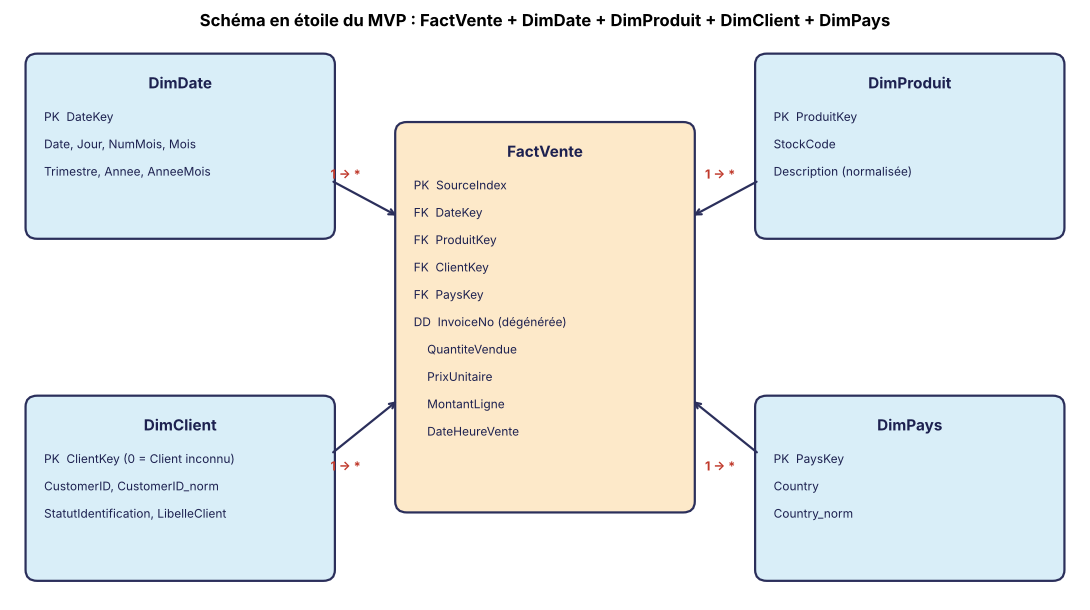

,DateKey,Date,Jour,Mois,Trimestre,Annee
177,20110713,2011-07-13,13,juillet,T3,2011
191,20110729,2011-07-29,29,juillet,T3,2011
207,20110817,2011-08-17,17,août,T3,2011
222,20110905,2011-09-05,5,septembre,T3,2011


Niveaux dans DimDate : ['Date (jour)', 'AnneeMois', 'Trimestre', 'Annee'] → aucune table par niveau
Tables du modèle : ['FactVente', 'DimDate', 'DimProduit', 'DimClient', 'DimPays']


In [13]:
# ÉTAPE 12 — Justifier l'architecture : étoile, flocon, entrepôt et mart
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# 1. Dictionnaire des grains, clés, références et attributs, calculé à partir des tables obtenues.
contrat_modele = pd.DataFrame([
    ["FactVente", len(fact_vente), "une ligne de vente observée d'un produit commercial", "SourceIndex",
     "DateKey, ProduitKey, ClientKey, PaysKey, InvoiceNo", "QuantiteVendue, PrixUnitaire, MontantLigne, DateHeureVente"],
    ["DimDate", len(dim_date), "un jour", "DateKey", "—", ", ".join(dim_date.columns[1:])],
    ["DimProduit", len(dim_produit), "un couple code / description normalisée", "ProduitKey", "—", "StockCode, Description"],
    ["DimClient", len(dim_client), "un client identifié ou le membre inconnu", "ClientKey", "—", ", ".join(dim_client.columns[1:])],
    ["DimPays", len(dim_pays), "un pays", "PaysKey", "—", "Country, Country_norm"],
], columns=["Table", "Lignes", "Grain", "Clé primaire", "Références", "Attributs / mesures"])
display(contrat_modele)

# 2. Schéma final en étoile : relations 1 → plusieurs (dimension → fait).
fig, ax = plt.subplots(figsize=(11, 6.2))
ax.set_xlim(0, 11); ax.set_ylim(0, 6.2); ax.axis("off")
def boite(x, y, w, h, titre, lignes, couleur):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.12",
                                fc=couleur, ec="#2b2f5b", lw=1.6))
    ax.text(x + w / 2, y + h - 0.28, titre, ha="center", va="center", fontsize=11, fontweight="bold", color="#1d2150")
    for i, l in enumerate(lignes):
        ax.text(x + 0.15, y + h - 0.65 - 0.3 * i, l, ha="left", va="center", fontsize=8.6, color="#1d2150")
boite(4.0, 1.0, 3.0, 4.2, "FactVente", ["PK  SourceIndex", "FK  DateKey", "FK  ProduitKey", "FK  ClientKey", "FK  PaysKey",
                                          "DD  InvoiceNo (dégénérée)", "    QuantiteVendue", "    PrixUnitaire",
                                          "    MontantLigne", "    DateHeureVente"], "#fde9c9")
boite(0.2, 4.0, 3.1, 1.95, "DimDate", ["PK  DateKey", "Date, Jour, NumMois, Mois", "Trimestre, Annee, AnneeMois"], "#d9eef8")
boite(7.7, 4.0, 3.1, 1.95, "DimProduit", ["PK  ProduitKey", "StockCode", "Description (normalisée)"], "#d9eef8")
boite(0.2, 0.25, 3.1, 1.95, "DimClient", ["PK  ClientKey (0 = Client inconnu)", "CustomerID, CustomerID_norm", "StatutIdentification, LibelleClient"], "#d9eef8")
boite(7.7, 0.25, 3.1, 1.95, "DimPays", ["PK  PaysKey", "Country", "Country_norm"], "#d9eef8")
for (x0, y0, x1, y1) in [(3.3, 4.6, 4.0, 4.2), (7.7, 4.6, 7.0, 4.2), (3.3, 1.6, 4.0, 2.2), (7.7, 1.6, 7.0, 2.2)]:
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="->", lw=1.6, color="#2b2f5b"))
for (x, y) in [(3.45, 4.62), (7.3, 4.62), (3.45, 1.42), (7.3, 1.42)]:
    ax.text(x, y, "1 → *", fontsize=9, fontweight="bold", color="#c0392b", ha="center")
ax.set_title("Schéma en étoile du MVP : FactVente + DimDate + DimProduit + DimClient + DimPays", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

# 3. Hiérarchie temporelle portée par DimDate (dans une seule table) : Jour -> Mois -> Trimestre -> Année.
display(dim_date[["DateKey", "Date", "Jour", "Mois", "Trimestre", "Annee"]].sample(4, random_state=1).sort_values("DateKey"))
print("Niveaux dans DimDate :", ["Date (jour)", "AnneeMois", "Trimestre", "Annee"], "→ aucune table par niveau")

# 4. Aucune table Catégorie, Marque, DimCommande ou autre : la source n'en contient pas.
print("Tables du modèle :", list(contrat_modele["Table"]))

### Preuve de l’étape
- **Variables ou tables obtenues :** `contrat_modele` (5 tables avec effectifs, grain, clé primaire), schéma en étoile dessiné (figure matplotlib), échantillon de hiérarchie de `DimDate`.
- **Résultat du contrôle / observations :** FactVente 522 364 · DimDate 305 · DimProduit 4 026 · DimClient 4 335 · DimPays 38 ; niveaux de DimDate : Date, AnneeMois, Trimestre, Annee, sans table par niveau.
- **Décision ou correction :** étoile retenue ; aucun flocon, aucune catégorie ni marque.

# ÉTAPE 13 — Défi technique : détecter une rupture d’intégrité
**Durée indicative : 10 min · Objectif :** Diagnostiquer une erreur sans supprimer une vente légitime.



## Questions du TP
1. Écrivez un contrôle qui identifie les clés de FactVente absentes d’une dimension, puis expliquez comment corriger le rattachement sans supprimer la ligne de vente.

## Question complémentaire — prendre du recul
Choisissez une erreur : référence produit dupliquée, référence absente, client inconnu perdu ou DateKey répétée. Quel contrôle doit échouer ? Le montant final pourrait-il rester correct malgré l’erreur ?

### Réponses

**Erreur choisie et prédiction avant le test :** **référence produit absente** (3 produits retirés par erreur de `DimProduit`, travail sur des copies). Prédiction : le contrôle de clés orphelines doit échouer pour `ProduitKey`, **mais** le total de `MontantLigne` du fait restera correct, car aucune ligne du fait n’est supprimée.  
**Contrôle déclenché / sortie observée :** avant l’erreur : 0 clé orpheline. Après : **3 clés orphelines `[1336, 3516, 3533]`**, **6 427 ventes** et **374 553,07** de montant concernés ; le total du fait reste **10 244 661,18** (écart avec L2 = 0). Diagnostic intercepté : « 3 clés ProduitKey du fait sont absentes de DimProduit ».  
**Cause et correction proposée :** cause : une dimension incomplète (membres retirés), alors que le fait référence toujours ces clés. Correction : **reconstruire/restaurer la dimension** (ou ajouter les membres manquants) puis refaire le lookup ; **ne jamais supprimer** les lignes de vente orphelines ni les rattacher à une clé arbitraire.  
**Preuve après correction :** 0 clé orpheline ; 522 364 lignes ; `ProduitKey` unique ; variante en jointure gauche : 6 427 lignes sans correspondance **conservées** (522 364 lignes). Les tables finales (`dim_produit` 4 026, `fact_vente` 522 364) sont intactes.

** justification :**  
Le contrôle repose sur `fait.isin(dimension)` : il liste les clés du fait absentes de la dimension, avec le nombre de ventes et le montant concernés.  
**Question complémentaire :** pour cette erreur, c’est le **contrôle des clés orphelines** qui doit échouer ; **le montant final peut rester correct** malgré l’erreur, d’où l’insuffisance d’un seul contrôle de total. Pour une **référence dupliquée**, ce serait l’unicité des clés (et l’effectif après jointure) ; pour un **client inconnu perdu**, la comparaison des provenances ; pour une **DateKey répétée**, le test d’unicité de DimDate.

**Point à vérifier / difficulté rencontrée :**  
Nous avons travaillé uniquement sur **des copies** pour ne pas corrompre L3 ; il faut penser à vérifier à la fin que les tables finales sont intactes.

In [14]:
# ÉTAPE 13 — Défi technique : détecter une rupture d'intégrité

# Erreur choisie : RÉFÉRENCE PRODUIT ABSENTE (des membres de DimProduit manquent alors que le fait les référence).
# Prédiction : le contrôle des clés orphelines doit échouer, alors que le total de MontantLigne restera correct.

# 1. Uniquement des COPIES de démonstration.
fact_demo = fact_vente.copy()
dim_produit_demo = dim_produit.copy()

def cles_orphelines(fait, dim, cle):
    """Retourne les clés du fait absentes de la dimension, le nombre de ventes et le montant concernés."""
    absentes = sorted(set(fait[cle].dropna()) - set(dim[cle]))
    concernees = fait[fait[cle].isin(absentes) | fait[cle].isna()]
    return absentes, concernees

# Avant l'erreur : la copie est saine.
absentes, concernees = cles_orphelines(fact_demo, dim_produit_demo, "ProduitKey")
print("AVANT erreur — clés ProduitKey orphelines :", len(absentes))

# 2. Une seule erreur contrôlée : 3 produits sont retirés de la copie de dimension (les plus vendus).
produits_retires = fact_demo["ProduitKey"].value_counts().index[:3]
dim_produit_demo = dim_produit_demo[~dim_produit_demo["ProduitKey"].isin(produits_retires)]

# 3. Le contrôle censé la détecter.
absentes, concernees = cles_orphelines(fact_demo, dim_produit_demo, "ProduitKey")
print("\nAPRÈS erreur — clés orphelines :", absentes)
print("Ventes concernées :", len(concernees), "| montant concerné :", f"{concernees['MontantLigne'].sum():,.2f}")
display(concernees[["SourceIndex", "InvoiceNo", "ProduitKey", "MontantLigne"]].head(5))
print("Total MontantLigne du fait (inchangé malgré l'erreur) :", f"{fact_demo['MontantLigne'].sum():,.2f}",
      "| écart avec L2 :", round(fact_demo["MontantLigne"].sum() - REF_MONTANT, 6))

# 4. Exception provoquée volontairement et interceptée de façon ciblée.
try:
    assert len(absentes) == 0, f"{len(absentes)} clés ProduitKey du fait sont absentes de DimProduit : {absentes}"
except AssertionError as e:
    print("\nDiagnostic intercepté :", e)

# 5. Correction SUR LA COPIE : on complète la dimension depuis les valeurs de L2 (aucune vente supprimée).
membres_manquants = dim_produit[dim_produit["ProduitKey"].isin(absentes)]
dim_produit_corrigee = pd.concat([dim_produit_demo, membres_manquants]).sort_values("ProduitKey").reset_index(drop=True)
absentes_apres, concernees_apres = cles_orphelines(fact_demo, dim_produit_corrigee, "ProduitKey")
assert len(fact_demo) == REF_LIGNES                       # aucune vente supprimée
assert len(absentes_apres) == 0 and dim_produit_corrigee["ProduitKey"].is_unique
print("\nAPRÈS correction — clés orphelines :", len(absentes_apres), "| lignes du fait :", len(fact_demo),
      "| clés ProduitKey uniques :", dim_produit_corrigee["ProduitKey"].is_unique)

# Variante : une jointure ne trouvant pas sa clé donne NaN ; elle doit aussi être détectée.
test_nan = fact_demo[["SourceIndex", "ProduitKey"]].merge(dim_produit_demo[["ProduitKey"]].assign(trouve=1),
                                                          on="ProduitKey", how="left")
print("Variante jointure gauche : lignes sans correspondance =", int(test_nan["trouve"].isna().sum()), "| lignes conservées =", len(test_nan))

# 6. Les tables finales destinées à l'export restent contrôlées (non modifiées par la démonstration).
assert cles_orphelines(fact_vente, dim_produit, "ProduitKey")[0] == []
assert len(dim_produit) == dim_produit["ProduitKey"].nunique() and len(fact_vente) == REF_LIGNES
print("Tables finales intactes : dim_produit =", len(dim_produit), "lignes | fact_vente =", len(fact_vente), "lignes")

AVANT erreur — clés ProduitKey orphelines : 0

APRÈS erreur — clés orphelines : [1336, 3516, 3533]
Ventes concernées : 6427 | montant concerné : 374,553.07


,SourceIndex,InvoiceNo,ProduitKey,MontantLigne
0,0,536365,3533,15.3
48,49,536373,3533,15.3
65,66,536375,3533,15.3
174,177,536386,3516,165.0
217,220,536390,3533,163.2


Total MontantLigne du fait (inchangé malgré l'erreur) : 10,244,661.18 | écart avec L2 : 0.0

Diagnostic intercepté : 3 clés ProduitKey du fait sont absentes de DimProduit : [1336, 3516, 3533]

APRÈS correction — clés orphelines : 0 | lignes du fait : 522364 | clés ProduitKey uniques : True
Variante jointure gauche : lignes sans correspondance = 6427 | lignes conservées = 522364


Tables finales intactes : dim_produit = 4026 lignes | fact_vente = 522364 lignes


### Preuve de l’étape
- **Variables ou tables obtenues :** copies `dim_produit_err`, `fact_err` ; `cles_orphelines` (diagnostic).
- **Résultat du contrôle / observations :** avant : 0 orphelin ; après erreur : 3 clés orphelines (1336, 3516, 3533), 6 427 ventes, 374 553,07 ; total du fait inchangé 10 244 661,18 ; après correction : 0 orphelin.
- **Décision ou correction :** dimension restaurée ; aucune vente supprimée ; tables finales intactes.

# ÉTAPE 14 — Exporter L3 et préparer le prochain TP OLAP
**Durée indicative : 15 min · Objectif :** Remettre un modèle alimenté et documenté, réutilisable.



## Questions du TP
1. Remettre la phrase de grain, le schéma en étoile, les tables DimDate/DimProduit/DimClient/DimPays et FactVente, le script ou notebook d’alimentation et les contrôles CP3–CP5.

## Question complémentaire — prendre du recul
Pour le prochain TP sur l’OLAP, proposer deux questions d’exploration possibles à partir de L3. Pour chacune : mesure, axes, niveau temporel, périmètre et contrôle de référence. Quelle question ne pouvez-vous pas traiter avec les attributs réellement disponibles ?

### Réponses

| Pièce L3 | Nom de fichier / emplacement | Contrôle avant remise |
|---|---|---|
| DimDate | `TP3_L3_DimDate.csv` (305 lignes) — `/kaggle/working` | Clés uniques, jours des ventes couverts, relecture OK |
| DimProduit | `TP3_L3_DimProduit.csv` (4 026 lignes) | Clés uniques, couples uniques, relecture OK |
| DimClient | `TP3_L3_DimClient.csv` (4 335 lignes) | Clés uniques, membre ClientKey 0 présent, relecture OK |
| DimPays | `TP3_L3_DimPays.csv` (38 lignes) | Clés uniques, relecture OK |
| FactVente | `TP3_L3_FactVente.csv` (522 364 lignes, ≈ 48,4 Mo) | 0 clé orpheline, quantité et montant égaux à L2 après relecture |
| Grain, schéma et contrôles | Phrase de grain (étape 2), schéma (étapes 4 et 12), `TP3_L3_CONTROLES.csv` (13 contrôles) | 13 contrôles « OK » |
| Notebook exécuté | Ce notebook (Kaggle), exécuté de haut en bas avec ses sorties | Aucune erreur ; relecture des CSV validée |

| Question pour le prochain TP OLAP | Mesure | Axes / niveau | Périmètre et contrôle |
|---|---|---|---|
| Comment évolue le chiffre d’affaires mensuel selon le pays ? | `MontantLigne` (somme) | Temps : **mois** (`AnneeMois`) × Pays | 522 364 ventes, 13 mois × 38 pays, y compris ventes sans client ; contrôle : total = **10 244 661,18** |
| Quels produits se vendent le plus, trimestre par trimestre ? | `QuantiteVendue` (somme) | Temps : **trimestre** × Produit | 522 364 ventes ; 14 978 groupes trimestre × produit ; contrôle : total = **5 561 117** |

**Une question non traitable et l’information manquante :** « Quel est le **taux de retour par catégorie de produit** ? » Impossible : (1) il n’existe **aucune catégorie** de produit dans L2 ; (2) les annulations/retours sont **hors du périmètre MVP** (exclus de L3). Information manquante : une table de catégories et les lignes de retour.

**justification :**  
Les cinq tables sont écrites dans `/kaggle/working`, puis **relues** pour vérifier lignes, références, provenances, client inconnu, quantités et montants. Les deux questions OLAP ont été testées en pratique (matrice mois × pays 13 × 38 et regroupement trimestre × produit) avec leurs totaux de contrôle, qui égalent ceux de L2.

**Point à vérifier / difficulté rencontrée :**  
Le CSV de `DimDate` stocke la date en texte `AAAA-MM-JJ` pour éviter qu’un outil la réinterprète ; `ClientKey = 0` reste bien dans `DimClient` et `CustomerID` y est vide (pas de faux identifiant).

In [15]:
# ÉTAPE 14 — Exporter L3 et préparer le prochain TP OLAP

# 1. Rejouer les contrôles sur les tables finales, après toute correction.
assert df_prep.shape[0] == REF_LIGNES and int(pd.util.hash_pandas_object(df_prep, index=False).sum()) == EMPREINTE_L2   # df_prep jamais modifié
for d, c in [(dim_date, "DateKey"), (dim_produit, "ProduitKey"), (dim_client, "ClientKey"), (dim_pays, "PaysKey")]:
    assert len(cles_orphelines(fact_vente, d, c)[0]) == 0 and fact_vente[c].notna().all(), f"clé orpheline : {c}"

# 2-4. Export CSV (utf-8-sig, sans index pandas) et controles_l3.
fichiers = {
    "TP3_L3_DimDate.csv": dim_date, "TP3_L3_DimProduit.csv": dim_produit, "TP3_L3_DimClient.csv": dim_client,
    "TP3_L3_DimPays.csv": dim_pays, "TP3_L3_FactVente.csv": fact_vente, "TP3_L3_CONTROLES.csv": controles_l3}
for nom, table in fichiers.items():
    if nom == "TP3_L3_DimDate.csv":
        table = table.assign(Date=table["Date"].dt.strftime("%Y-%m-%d"))     # jour seul : AAAA-MM-JJ
    table.to_csv(DOSSIER_SORTIE / nom, index=False, encoding="utf-8-sig", date_format="%Y-%m-%d %H:%M:%S")

# 5. Relecture en protégeant identifiants et types.
relu = {
    "DimDate": pd.read_csv(DOSSIER_SORTIE / "TP3_L3_DimDate.csv", encoding="utf-8-sig", parse_dates=["Date"]),
    "DimProduit": pd.read_csv(DOSSIER_SORTIE / "TP3_L3_DimProduit.csv", encoding="utf-8-sig", dtype={"StockCode": str, "Description": str}),
    "DimClient": pd.read_csv(DOSSIER_SORTIE / "TP3_L3_DimClient.csv", encoding="utf-8-sig",
                             dtype={"CustomerID": str, "CustomerID_norm": str}, keep_default_na=False, na_values=[""]),
    "DimPays": pd.read_csv(DOSSIER_SORTIE / "TP3_L3_DimPays.csv", encoding="utf-8-sig", dtype={"Country": str, "Country_norm": str}),
    "FactVente": pd.read_csv(DOSSIER_SORTIE / "TP3_L3_FactVente.csv", encoding="utf-8-sig",
                             dtype={"InvoiceNo": str, "SourceFile": str}, parse_dates=["DateHeureVente"]),
}
# 6. Lignes, références et montants après relecture.
assert {k: len(v) for k, v in relu.items()} == {"DimDate": len(dim_date), "DimProduit": len(dim_produit), "DimClient": len(dim_client),
                                               "DimPays": len(dim_pays), "FactVente": len(fact_vente)}
f = relu["FactVente"]
assert len(f) == REF_LIGNES and set(f["SourceIndex"]) == REF_SOURCEINDEX and f["SourceIndex"].is_unique
assert (f["InvoiceNo"].to_numpy() == fact_vente["InvoiceNo"].to_numpy()).all()                                           # identifiants intacts (texte)
for cle, dim in [("DateKey", "DimDate"), ("ProduitKey", "DimProduit"), ("ClientKey", "DimClient"), ("PaysKey", "DimPays")]:
    assert set(f[cle]) <= set(relu[dim][cle]), f"clé orpheline après relecture : {cle}"
assert set(f.loc[f["ClientKey"] == 0, "SourceIndex"]) == REF_SANS_CLIENT
assert np.isclose(f["MontantLigne"].sum(), REF_MONTANT, rtol=1e-12, atol=1e-9) and f["QuantiteVendue"].sum() == REF_QUANTITE
assert relu["DimClient"].loc[relu["DimClient"]["ClientKey"] == 0, "CustomerID"].isna().all()    # pas de faux CustomerID
print("Contrôles de relecture réussis : lignes, références, provenances, client inconnu, quantités et montants.")

controle_relecture = pd.DataFrame({"Fichier": list(fichiers), "Lignes": [len(t) for t in fichiers.values()],
    "Taille (Mo)": [round((DOSSIER_SORTIE / n).stat().st_size / 1e6, 2) for n in fichiers]})
display(controle_relecture)
print("Fichiers produits :", sorted(p.name for p in DOSSIER_SORTIE.glob("TP3_L3_*.csv")))

# Pour le prochain TP OLAP : les deux questions sont réalisables avec les seuls attributs de L3.
q1 = (fact_vente.merge(dim_date[["DateKey", "AnneeMois"]], on="DateKey").merge(dim_pays[["PaysKey", "Country"]], on="PaysKey")
      .groupby(["AnneeMois", "Country"])["MontantLigne"].sum().unstack("Country").fillna(0))
print("\nQ1 — Montant par mois × pays :", q1.shape, "| total contrôle =", f"{q1.to_numpy().sum():,.2f}")
q2 = (fact_vente.merge(dim_date[["DateKey", "Trimestre", "Annee"]], on="DateKey").merge(dim_produit, on="ProduitKey")
      .groupby(["Annee", "Trimestre", "Description"])["QuantiteVendue"].sum())
print("Q2 — Quantité par trimestre × produit :", q2.shape, "| total contrôle =", f"{q2.sum():,.0f}")
display(q1.sum(axis=1).rename("Montant (tous pays)").to_frame().T.round(0))
assert np.isclose(q1.to_numpy().sum(), REF_MONTANT, rtol=1e-12, atol=1e-9) and q2.sum() == REF_QUANTITE

Contrôles de relecture réussis : lignes, références, provenances, client inconnu, quantités et montants.


,Fichier,Lignes,Taille (Mo)
0,TP3_L3_DimDate.csv,305,0.01
1,TP3_L3_DimProduit.csv,4026,0.16
2,TP3_L3_DimClient.csv,4335,0.18
3,TP3_L3_DimPays.csv,38,0.00
4,TP3_L3_FactVente.csv,522364,48.38
5,TP3_L3_CONTROLES.csv,13,0.00


Fichiers produits : ['TP3_L3_CONTROLES.csv', 'TP3_L3_DimClient.csv', 'TP3_L3_DimDate.csv', 'TP3_L3_DimPays.csv', 'TP3_L3_DimProduit.csv', 'TP3_L3_FactVente.csv']

Q1 — Montant par mois × pays : (13, 38) | total contrôle = 10,244,661.18


Q2 — Quantité par trimestre × produit : (14978,) | total contrôle = 5,561,117


AnneeMois,2010-12,2011-01,2011-02,2011-03,2011-04,2011-05,2011-06,2011-07,2011-08,2011-09,2011-10,2011-11,2011-12
Montant (tous pays),775638.0,670205.0,507800.0,689834.0,515378.0,739812.0,737131.0,687960.0,724035.0,1028037.0,1103040.0,1451583.0,614210.0


### Preuve de l’étape
- **Variables ou tables obtenues :** `TP3_L3_DimDate.csv`, `…DimProduit.csv`, `…DimClient.csv`, `…DimPays.csv`, `…FactVente.csv`, `…CONTROLES.csv` ; tables relues `rel_*` ; requêtes d’essai `q1` et `q2`.
- **Résultat du contrôle / observations :** « Contrôles de relecture réussis » (lignes, références, provenances, client inconnu, quantités, montants) ; Q1 : (13 × 38), total 10 244 661,18 ; Q2 : 14 978 groupes, total 5 561 117.
- **Décision ou correction :** L3 prêt pour le prochain TP OLAP.

# Bilan  — prêt pour l’OLAP ?

Cocher seulement après avoir produit la preuve correspondante.

- [x] Nous pouvons expliquer le grain sans citer uniquement une clé technique. *(étape 2 : phrase de grain testée sur les données)*
- [x] Nous distinguons une mesure, un identifiant et un attribut descriptif. *(étape 3)*
- [x] Les quatre dimensions du MVP existent et leurs clés sont uniques. *(étapes 5 à 8 : 305 · 4 026 · 4 335 · 38)*
- [x] Le fait conserve InvoiceNo, les mesures et les références attendues. *(étape 10)*
- [x] Les ventes admissibles ne sont ni perdues ni multipliées. *(étapes 9 et 11 : 522 364 provenances identiques)*
- [x] Le client inconnu est conservé et le pays reste exploitable. *(131 355 ventes sur ClientKey 0, `PaysKey` renseigné pour chacune)*
- [x] Les références absentes sont diagnostiquées, pas masquées. *(étape 13)*
- [x] Les montants sont réconciliés avec L2 et après relecture des CSV. *(10 244 661,18)*
- [x] Les données et commentaires permettent à un autre binôme de reproduire L3. *(code commenté, règles de clés documentées, chemin détecté automatiquement)*
- [x] Nous avons formulé deux questions pour le prochain TP **OLAP**. *(étape 14)*

**principale difficulté et ce que nous avons appris :**  
La principale difficulté a été de **ne perdre ni dupliquer aucune vente** pendant le rattachement des clés. Nous avons appris que : (1) l’**ordre des opérations** compte (réduire l’horodatage au jour avant de dédoublonner DimDate) ; (2) une jointure sur le code produit seul ajoute 53 073 lignes à cause de 212 codes à plusieurs descriptions ; (3) les ventes sans client (25 % des lignes) doivent être conservées par un membre « Client inconnu », pas supprimées ; (4) un **total correct ne prouve pas** l’intégrité : il faut comparer les provenances, les lignes et les groupes.

**Point qui reste à clarifier avant le prochain TP :**  
(1) La règle de gestion des 3 couples facture + produit à quantité et prix identiques (doublon métier ou vente répétée ?) ; (2) la normalisation des espaces multiples dans `Description_norm` (19 532 valeurs), qui ferait passer les produits de 4 026 à 4 020 ; (3) l’intérêt d’un calendrier complet (tous les jours) dans DimDate.

## Pour aller plus loin — facultatif, après le parcours essentiel
1. **Conserver les clés lors de chargements successifs :** il faudrait garder la **table de correspondance** valeur naturelle → clé (par exemple `StockCode` + description → `ProduitKey`), **réutiliser** les clés existantes et n’attribuer de nouvelles clés (max + 1) qu’aux nouveaux membres. Renuméroter une dimension peut invalider les anciennes références : un fait déjà chargé avec `ProduitKey = 3533` pointerait vers un autre produit (ou vers rien) si la numérotation change.
2. **Plusieurs tables de faits :** **oui**, un Data Mart peut avoir plusieurs faits (constellation) qui partagent des dimensions conformes (date, produit). Il faut préciser le grain de chacun (ex. une ligne de vente vs un état de stock à une date) avant de les comparer : additionner ou rapprocher des mesures de grains différents fausse les résultats (le stock n’est pas additif dans le temps comme une quantité vendue).
3. **Idempotence :** relancer le même chargement initial avec la **même entrée et les mêmes règles** doit produire **exactement le même état final** (mêmes lignes, mêmes clés, mêmes totaux), sans doublons. Une **reconstruction contrôlée** (on vide ou recrée les tables puis on les recharge) est idempotente ; un **ajout répété de lignes** (append à chaque exécution) double le fait à chaque relance.


